# Import Library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import cmath
import csv
import time

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.layers import Dense, Conv1D, Flatten, GRU, Input, MaxPooling1D, concatenate, BatchNormalization, Reshape
from tensorflow.keras.losses import MeanSquaredError, MeanAbsolutePercentageError
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

In [ ]:
from scipy.interpolate import interp1d

# Fungsi Penting

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)

  return depth_plot, resis_plot

In [ ]:
def measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # MSE untuk resistivitas_semu
  mse_resistivitas = np.mean(np.square(resistivitas_semu - resistivitas_semu_predict))

  # MSE untuk fasa
  mse_fasa = np.mean(np.square(fasa - fasa_predict))

  # Cetak hasil
  print(f"MSE Resistivitas Semu: {mse_resistivitas:.2f}")
  print(f"MSE Fasa: {mse_fasa:.2f}")

In [ ]:
def measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # Hitung MAPE
  mape = np.mean(np.abs((resistivitas_semu - resistivitas_semu_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE resistivitas semu: {mape:.2f}%")
  # Hitung MAPE
  mape = np.mean(np.abs((fasa - fasa_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE fasa: {mape:.2f}%")

In [ ]:
def measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth):
  # Formating data
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)

  # Definisikan grid kedalaman umum
  common_depths = np.linspace(0, 4000, 200)

  # Interpolasi ke grid umum
  interp_true = interp1d(depth_true_plot, resis_true_plot, kind='previous', fill_value='extrapolate')
  interp_pred = interp1d(depth_pred_plot, resis_pred_plot, kind='previous', fill_value='extrapolate')

  res_true_interp = interp_true(common_depths)
  res_pred_interp = interp_pred(common_depths)

  # Sekarang bisa dibandingkan secara numerik juga
  mse_interp = mean_squared_error(res_true_interp, res_pred_interp)
  mape_interp = mean_absolute_percentage_error(res_true_interp, res_pred_interp)

  print(f"[Interpolated] MSE model resistivitas: {mse_interp:.4f}")
  print(f"[Interpolated] MAPE model resistivitas: {mape_interp*100:.2f}%")

  plt.figure(figsize=(8, 6))

  # Plot garis hasil interpolasi
  plt.scatter(res_true_interp, common_depths, label='True (Interpolated)', color='blue', linewidth=2)
  plt.scatter(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  plt.scatter(res_pred_interp, common_depths, label='Predicted (Interpolated)', color='red', linestyle='--', linewidth=2)

  # Sumbu y dibalik agar makin dalam ke bawah
  plt.gca().invert_yaxis()

  # Label dan judul
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Perbandingan Interpolasi Resistivitas Sebenarnya vs Prediksi', fontsize=14)
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xlim(0, 1000)
  plt.ylim(4000,0)

  plt.show()


In [ ]:
def plot_model(resis_predict, ketebalan_predict ,total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)
  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:

def plot_model_compare(res_true, ketebalan_true, res_predict, ketebalan_predict, total_depth):
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 1200)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:
def plot_MT(resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):


  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.plot(period, resistivitas_semu[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax1.plot(period, resistivitas_semu_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
  ax1.set_xlabel('Periods (Sec.)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_ylim([0, 1000])
  ax1.set_xlim([10**-4, 10**4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.plot(period, fasa[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax2.plot(period, fasa_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax2.set_ylabel('Phase [derajat]', fontsize=12)
  ax2.set_xlabel('Periods (Sec.)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([0, 90])
  ax2.set_xlim([10**-4, 10**4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  # Subplot 3: Resistivitas Prediksi (span 2 baris)
  ax3 = fig.add_subplot(gs[:, 1])  # Ini artinya: kolom ke-2, tapi mencakup dua baris
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm.m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 1200)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()


In [ ]:
def plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):

  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.plot(period, resistivitas_semu[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax1.plot(period, resistivitas_semu_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
  ax1.set_xlabel('Periods (Sec.)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_ylim([0, 1200])
  ax1.set_xlim([10**-4, 10**4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.plot(period, fasa[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax2.plot(period, fasa_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax2.set_ylabel('Phase [derajat]', fontsize=12)
  ax2.set_xlabel('Periods (Sec.)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([0, 90])
  ax2.set_xlim([10**-4, 10**4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  # Subplot 3: Resistivitas Prediksi (span 2 baris)
  ax3 = fig.add_subplot(gs[:, 1])  # Ini artinya: kolom ke-2, tapi mencakup dua baris
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linestyle ='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm.m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 1200)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()


#Forward Modelling

In [ ]:
#Fungsi forward modelling
def forward_modelling(res_true, ketebalan, frequencies):
    resistivitas_semu = np.array([])
    fasa = np.array([])
    for frequency in frequencies:
        w = 2 * np.pi * frequency
        mu = 4 * np.pi * 10**(-7)
        n = len(res_true)
        Z = list(range(n))  # Initialize Z as a list
        Z[n-1] = cmath.sqrt(w * mu * res_true[n-1] * 1j)  # Calculate basement impedance
        for j in range(n-2, -1, -1):
            Z0j = cmath.sqrt(1j * w * mu * res_true[j])  # Intrinsic impedance of current layer
            kj = cmath.sqrt(1j * w * mu / res_true[j])  # Wave number
            ej = cmath.exp(-2 * ketebalan[j] * kj)  # Exponential factor
            Rj = (Z0j - Z[j+1]) / (Z0j + Z[j+1])  # Reflection coefficient
            Z[j] = Z0j * (1 - Rj * ej) / (1 + Rj * ej)  # Impedance of current layer
        Z_intrinsik = Z[0]  # Top layer impedance
        absZ = abs(Z_intrinsik)
        appres = (absZ * absZ) / (mu * w)  # Apparent resistivity
        phase = np.degrees(cmath.phase(Z_intrinsik))  # Phase in degrees
        resistivitas_semu = np.append(resistivitas_semu, appres)
        fasa = np.append(fasa, phase)
    return resistivitas_semu, fasa  # Return the arrays

#Pembuatan Dataset

In [ ]:
import numpy as np
import time



# Parameter dataset
jumlah_data = 1000000  # contoh 10 ribu dulu untuk testing
jumlah_layer = 20
total_depth = 4000  # meter
layer_thickness = total_depth / jumlah_layer  # 200 meter
frequencies = np.logspace(-4, 4, num=60)  # 60 frekuensi logaritmik
sampel_resistivitas = np.arange(1, 1001, 1)  # Resistivitas dari 1-1000 Ohm.m

In [ ]:
# Start timer
start = time.time()

# Inisialisasi list untuk dataset
input_res_list = []
input_phase_list = []
output_model_list = []

# Loop pembuatan dataset
for i in range(jumlah_data):
    # Random p untuk probabilitas resistivitas tetap
    p = np.random.uniform(0.4, 1.0)

    # Mulai membuat model resistivitas
    resistivities = []
    res_awal = np.random.choice(sampel_resistivitas)
    resistivities.append(res_awal)

    for j in range(1, jumlah_layer):
        if np.random.rand() < p:
            # Sama dengan resistivitas sebelumnya
            resistivities.append(resistivities[-1])
        else:
            # Pilih resistivitas baru
            resistivities.append(np.random.choice(sampel_resistivitas))

    resistivities = np.array(resistivities)

    # Karena ketebalan layer tetap 200m, kita bisa buat array ketebalan langsung
    thicknesses = np.full(jumlah_layer, layer_thickness)

    # Forward modeling - kamu perlu pastikan punya fungsi ini
    resistivitas_semu, fasa = forward_modelling(resistivities, thicknesses, frequencies)

    # Gabungkan output model: bisa resistivitas saja atau resistivitas + ketebalan
    output_model = resistivities  # karena ketebalan fix, biasanya cukup resistivitas saja

    # Simpan data ke list
    input_res_list.append(resistivitas_semu)
    input_phase_list.append(fasa)
    output_model_list.append(output_model)

# Konversi list ke numpy array
input_res_array = np.array(input_res_list)
input_phase_array = np.array(input_phase_list)
output_model_array = np.array(output_model_list)

# End timer
end = time.time()
print(f"Dataset dibuat dalam {(end-start)/60:.2f} menit")


Dataset dibuat dalam 117.41 menit


In [ ]:
df_input_res = pd.DataFrame(input_res_array)
df_input_phase = pd.DataFrame(input_phase_array)
df_output_model = pd.DataFrame(output_model_array)

df_input_res.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_3.csv', index=False)
df_input_phase.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_3.csv', index=False)
df_output_model.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_3.csv', index=False)

#Membaca dataset, normalisasi dan standarisasi

In [ ]:
df_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_3.csv')
df_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_3.csv')
df_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_3.csv')

In [ ]:
input_res_readed = df_input_res.to_numpy()
input_phase_readed = df_input_phase.to_numpy()
output_model_readed = df_output_model.to_numpy()

In [ ]:
input_res_readed = input_res_readed.reshape(input_res_readed.shape[0], input_res_readed.shape[1])
input_phase_readed = input_phase_readed.reshape(input_phase_readed.shape[0], input_phase_readed.shape[1])
output_model_readed = output_model_readed.reshape(output_model_readed.shape[0], output_model_readed.shape[1])

In [ ]:
input_res_scaler = MinMaxScaler(feature_range=(0, 1))
input_phase_scaler = MinMaxScaler(feature_range=(0, 1))
output_model_scaler = MinMaxScaler(feature_range=(0, 1))



In [ ]:
input_res_scaled = input_res_scaler.fit_transform(input_res_readed)
input_phase_scaled = input_phase_scaler.fit_transform(input_phase_readed)
output_model_scaled = output_model_scaler.fit_transform(output_model_readed)

In [ ]:
df_input_res_scaled = pd.DataFrame(input_res_scaled)
df_input_phase_scaled = pd.DataFrame(input_phase_scaled)
df_output_model_scaled = pd.DataFrame(output_model_scaled)

In [ ]:
df_input_res_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_3.csv', index=False)
df_input_phase_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_3.csv', index=False)
df_output_model_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_3.csv', index=False)

#Membaca Dataset Normalisasi dan data Splitting

In [ ]:
df_X_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_3.csv')
df_X_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_3.csv')
df_Y_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_3.csv')

In [ ]:
X_input_res = df_X_input_res.to_numpy()
X_input_phase = df_X_input_phase.to_numpy()
Y_output_model = df_Y_output_model.to_numpy()

In [ ]:
X_input_res_reshape = X_input_res.reshape(X_input_res.shape[0], X_input_res.shape[1], 1)
X_input_phase_reshape = X_input_phase.reshape(X_input_phase.shape[0], X_input_phase.shape[1], 1)
Y_output_model_reshape = Y_output_model.reshape(Y_output_model.shape[0], Y_output_model.shape[1])

In [ ]:
# Bagi data menjadi training dan gabungan validation/test
X_train_res, X_val_res, X_train_phase, X_val_phase, y_train, y_val = train_test_split(
    X_input_res_reshape, X_input_phase_reshape, Y_output_model_reshape, test_size=0.1, random_state=42
)




In [ ]:
X_train = [X_train_res, X_train_phase]
X_val = [X_val_res, X_val_phase]

# Model CNN-GRU

In [ ]:
def CNN_GRU_Model_Scratch():

    #Input
    input_res = Input(shape=(X_train_res.shape[1],1), name = "input_res")
    input_phase = Input(shape=(X_train_phase.shape[1],1), name = "input_phase")

    # Convolusi input res
    x1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_res) # Changed stride to strides
    x1 = MaxPooling1D(pool_size=2)(x1)
    x1 = Conv1D(filters=32, kernel_size=2, strides=1, activation='relu', padding = 'same')(x1)
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Flatten()(x1)

    # Convolusi input phase
    z1 = Conv1D(filters=16, kernel_size=2, strides=1, activation='relu', padding = 'same')(input_phase) # Changed stride to strides
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=2, strides=1,  activation='relu', padding = 'same')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Flatten()(z1)

    merge = concatenate([x1, z1])
    dense_layer = Dense(128, activation = "relu")(merge) # Changed Dense to dense_layer
    # Reshape the output of the dense layer to be 3D for the GRU layer
    reshape_layer = layers.Reshape((1, dense_layer.shape[-1]))(dense_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid")(reshape_layer) # Changed Dense to dense_layer and Gru to gru_layer

    output = Dense(Y_output_model_reshape.shape[1])(gru_layer)  # Access the output shape using Y_output_model_reshape and apply the Dense layer to gru_layer

    model = Model(inputs=[input_res, input_phase], outputs=output)

    return model

In [ ]:
def CNN_GRU_Model_Improved():

    #Input
    input_res = Input(shape=(X_train_res.shape[1],1), name = "input_res")
    input_phase = Input(shape=(X_train_phase.shape[1],1), name = "input_phase")

    # Convolusi input res
    x1 = Conv1D(filters=16, kernel_size=3, strides=1, padding = 'same', activation='relu')(input_res) # Changed stride to strides
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Conv1D(filters=32, kernel_size=3, padding = 'same',  activation='relu')(x1)
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Conv1D(filters=32, kernel_size=2, padding = 'same', activation='relu')(x1)
    X1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    X1 = Conv1D(filters=32, kernel_size=2, padding = 'same',  activation='relu')(x1)
    x1 = MaxPooling1D(pool_size=2, strides=1)(x1)
    x1 = Flatten()(x1)

    # Convolusi input phase
    z1 = Conv1D(filters=16, kernel_size=3, strides=1, padding = 'same', activation='relu')(input_phase) # Changed stride to strides
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=3, strides=1, padding = 'same', activation='relu')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=2, strides=1, padding = 'same', activation='relu')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)
    z1 = Conv1D(filters=32, kernel_size=2, strides=1, padding = 'same', activation='relu')(z1)
    z1 = MaxPooling1D(pool_size=2, strides=1)(z1)

    z1 = Flatten()(z1)

    merge = concatenate([x1, z1])
    dense_layer = Dense(128, activation = "relu")(merge) # Changed Dense to dense_layer
    # Reshape the output of the dense layer to be 3D for the GRU layer
    reshape_layer = layers.Reshape((1, dense_layer.shape[-1]))(dense_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid", return_sequences= True)(reshape_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid", return_sequences= True)(gru_layer)
    gru_layer = GRU(32, activation= "tanh", recurrent_activation="sigmoid")(gru_layer) # Changed Dense to dense_layer and Gru to gru_layer

    output = Dense(Y_output_model_reshape.shape[1])(gru_layer)  # Access the output shape using Y_output_model_reshape and apply the Dense layer to gru_layer

    model = Model(inputs=[input_res, input_phase], outputs=output)

    return model

In [ ]:
model = CNN_GRU_Model_Improved()

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_phase         │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 60, 16)    │         64 │ input_phase[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_res           │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 59, 16)    │          0 │ conv1d_4[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 60, 16)    │         64 │ input_res[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 59, 32)    │      1,568 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 59, 16)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 58, 32)    │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 59, 32)    │      1,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 58, 32)    │      2,080 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 58, 32)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 57, 32)    │          0 │ conv1d_6[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 58, 32)    │      2,080 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 57, 32)    │      2,080 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 57, 32)    │          0 │ conv1d_2[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_7     │ (None, 56, 32)    │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 1824)      │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1792)      │          0 │ max_pooling1d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3616)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    462,976 │ concatenate[0][0

 Total params: 501,364 (1.91 MB)

 Trainable params: 501,364 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [EarlyStopping(monitor='val_loss', patience=15, verbose=1, restore_best_weights=True)]

In [ ]:
    checkpoint_filepath = '/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_model2.h5' # Choose a path in your Drive
    model_checkpoint_callback = ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=False, # Set to True if you only want to save weights
        monitor='val_loss',
        mode='min',
        save_best_only=True)

In [ ]:
    # Use Adam optimizer with learning rate scheduling
model.compile(optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
start = time.time()
history = model.fit(
    x=[X_train_res, X_train_phase],
    y=y_train,
    epochs=200,
    batch_size=16,  # sesuai paper
    validation_data=([X_val_res, X_val_phase], y_val),
    verbose=1,
    callbacks = [callbacks, model_checkpoint_callback]
)
end = time.time()
print(f"Waktu eksekusi: {(end - start) / 60:.2f} menit")

Epoch 1/200
56247/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0473 - loss: 0.0473

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 551s 10ms/step - MSE: 0.0473 - loss: 0.0473 - val_MSE: 0.0304 - val_loss: 0.0304
Epoch 2/200
56248/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0289 - loss: 0.0289

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 543s 10ms/step - MSE: 0.0289 - loss: 0.0289 - val_MSE: 0.0266 - val_loss: 0.0266
Epoch 3/200
56246/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0255 - loss: 0.0255

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 544s 10ms/step - MSE: 0.0255 - loss: 0.0255 - val_MSE: 0.0242 - val_loss: 0.0242
Epoch 4/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0238 - loss: 0.0238

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 552s 10ms/step - MSE: 0.0238 - loss: 0.0238 - val_MSE: 0.0231 - val_loss: 0.0231
Epoch 5/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0227 - loss: 0.0227

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 558s 10ms/step - MSE: 0.0227 - loss: 0.0227 - val_MSE: 0.0226 - val_loss: 0.0226
Epoch 6/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - MSE: 0.0219 - loss: 0.0219

... (54 outputs left out)

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 558s 10ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 129/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 612s 11ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 130/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 551s 10ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 131/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 575s 10ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0138 - val_loss: 0.0138
Epoch 132/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 568s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0139 - val_loss: 0.0139
Epoch 133/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 590s 10ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0137 - val_loss: 0.0137
Epoch 134/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 579s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0137 - val_loss: 0.0137
Epoch 135/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 563s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0136 - val_los

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 564s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 137/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 566s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0138 - val_loss: 0.0138
Epoch 138/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 580s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0137 - val_loss: 0.0137
Epoch 139/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 600s 11ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 140/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - MSE: 0.0133 - loss: 0.0133

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 605s 11ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0135 - val_loss: 0.0135
Epoch 141/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 570s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0138 - val_loss: 0.0138
Epoch 142/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 581s 10ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 143/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 558s 10ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 144/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 625s 11ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 145/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 569s 10ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0137 - val_loss: 0.0137
Epoch 146/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 557s 10ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0135 - val_loss: 0.0135
Epoch 147/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 557s 10ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0136 - val_los

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 563s 10ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0134 - val_loss: 0.0134
Epoch 149/200
 2831/56250 ━━━━━━━━━━━━━━━━━━━━ 8:28 10ms/step - MSE: 0.0132 - loss: 0.0132

In [ ]:
# Load the saved model from the checkpoint
loaded_model = tf.keras.models.load_model(checkpoint_filepath) # Use the path you defined for ModelCheckpoint

In [ ]:
# Print model summary to check input shape
loaded_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_phase         │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 60, 16)    │         64 │ input_phase[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_res           │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 59, 16)    │          0 │ conv1d_4[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 60, 16)    │         64 │ input_res[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 59, 32)    │      1,568 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 59, 16)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 58, 32)    │          0 │ conv1d_5[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 59, 32)    │      1,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 58, 32)    │      2,080 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 58, 32)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 57, 32)    │          0 │ conv1d_6[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 58, 32)    │      2,080 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 57, 32)    │      2,080 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 57, 32)    │          0 │ conv1d_2[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_7     │ (None, 56, 32)    │          0 │ conv1d_7[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 1824)      │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1792)      │          0 │ max_pooling1d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3616)      │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    462,976 │ concatenate[0][0

 Total params: 1,002,730 (3.83 MB)

 Trainable params: 501,364 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 501,366 (1.91 MB)

In [ ]:
    checkpoint_filepath = '/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_model3.h5' # Choose a path in your Drive
    model_checkpoint_callback = ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=False, # Set to True if you only want to save weights
        monitor='val_loss',
        mode='min',
        save_best_only=True)

In [ ]:
# Compile the loaded model (use the same optimizer, loss, and metrics as before)
loaded_model.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.0001),
                      loss=tf.keras.losses.MeanSquaredError(),
                      metrics=['MSE'])

In [ ]:
# Continue training
start = time.time()

history = loaded_model.fit(x=[X_train_res, X_train_phase],
                           y=y_train,
                           epochs=200,  # Continue for the desired number of epochs
                           initial_epoch = 148,
                           batch_size=16, # Changed batch size back to 16
                           validation_data=([X_val_res, X_val_phase], y_val),
                           callbacks=[callbacks, model_checkpoint_callback]) # Include callbacks again
end = time.time()
print(f"Waktu eksekusi: {(end - start) / 60} menit")

Epoch 149/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - MSE: 0.0143 - loss: 0.0143

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 812s 14ms/step - MSE: 0.0143 - loss: 0.0143 - val_MSE: 0.0138 - val_loss: 0.0138
Epoch 150/200
56247/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MSE: 0.0134 - loss: 0.0134

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 793s 14ms/step - MSE: 0.0134 - loss: 0.0134 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 151/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MSE: 0.0133 - loss: 0.0133

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 796s 14ms/step - MSE: 0.0133 - loss: 0.0133 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 152/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 797s 14ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0137 - val_loss: 0.0137
Epoch 153/200
56246/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MSE: 0.0132 - loss: 0.0132

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 791s 14ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 154/200
56247/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MSE: 0.0132 - loss: 0.0132

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 790s 14ms/step - MSE: 0.0132 - loss: 0.0132 - val_MSE: 0.0135 - val_loss: 0.0135
Epoch 155/200
56248/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MSE: 0.0131 - loss: 0.0131

... (2 outputs left out)

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 800s 14ms/step - MSE: 0.0131 - loss: 0.0131 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 159/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 818s 15ms/step - MSE: 0.0131 - loss: 0.0131 - val_MSE: 0.0136 - val_loss: 0.0136
Epoch 160/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 820s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0134 - val_loss: 0.0134
Epoch 161/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 830s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0135 - val_loss: 0.0135
Epoch 162/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 838s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 163/200
56248/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - MSE: 0.0130 - loss: 0.0130

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 831s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 164/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 831s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 165/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 832s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 166/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 835s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 167/200
56248/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - MSE: 0.0130 - loss: 0.0130

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 838s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 168/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 832s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0134 - val_loss: 0.0134
Epoch 169/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 845s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0135 - val_loss: 0.0135
Epoch 170/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 838s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 171/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 839s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 172/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 845s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 173/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 829s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0134 - val_loss: 0.0134
Epoch 174/200
56249/56250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - MSE: 0.0130 - loss: 0.0130

56250/56250 ━━━━━━━━━━━━━━━━━━━━ 836s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0132 - val_loss: 0.0132
Epoch 175/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 831s 15ms/step - MSE: 0.0129 - loss: 0.0129 - val_MSE: 0.0134 - val_loss: 0.0134
Epoch 176/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 826s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 177/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 832s 15ms/step - MSE: 0.0129 - loss: 0.0129 - val_MSE: 0.0132 - val_loss: 0.0132
Epoch 178/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 839s 15ms/step - MSE: 0.0129 - loss: 0.0129 - val_MSE: 0.0132 - val_loss: 0.0132
Epoch 179/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 827s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0133 - val_loss: 0.0133
Epoch 180/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 834s 15ms/step - MSE: 0.0130 - loss: 0.0130 - val_MSE: 0.0132 - val_loss: 0.0132
Epoch 181/200
56250/56250 ━━━━━━━━━━━━━━━━━━━━ 827s 15ms/step - MSE: 0.0129 - loss: 0.0129 - val_MSE: 0.0132 - val_los

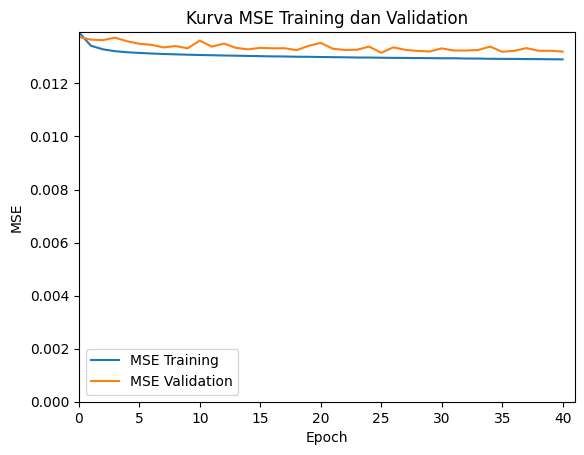

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.plot(mse_training, label='MSE Training')
plt.plot(mse_validation, label='MSE Validation')
plt.title('Kurva MSE Training dan Validation')
plt.xlim(0, len(mse_training))
plt.ylim(0, max(mse_training))
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

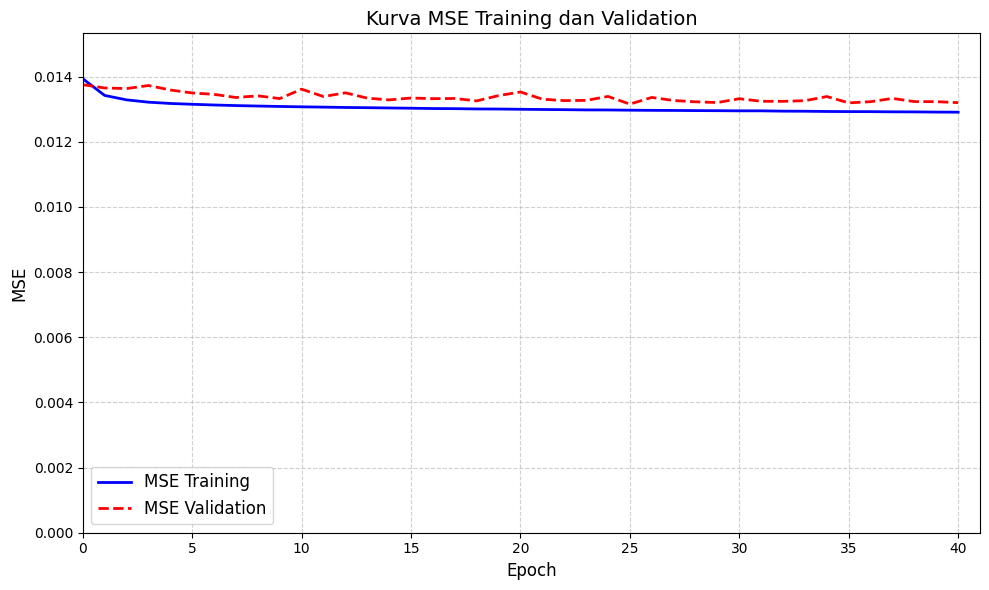

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.figure(figsize=(10, 6))  # Adjust figure size for better visualization
plt.plot(mse_training, label='MSE Training', color='blue', linewidth=2)  # Customize line style
plt.plot(mse_validation, label='MSE Validation', color='red', linestyle='--', linewidth=2)  # Customize line style
plt.title('Kurva MSE Training dan Validation', fontsize=14)  # Increase title font size
plt.xlabel('Epoch', fontsize=12)  # Increase label font size
plt.ylabel('MSE', fontsize=12)  # Increase label font size
plt.xlim(0, len(mse_training))  # Set x-axis limit to the number of epochs
plt.ylim(0, max(max(mse_training), max(mse_validation)) * 1.1)  # Adjust y-axis limit for better visualization
plt.grid(True, linestyle='--', alpha=0.6)  # Add grid for better readability
plt.legend(fontsize=12)  # Increase legend font size
plt.tight_layout()  # Adjust layout to prevent labels from overlapping
plt.show()

In [ ]:
# ... (your model training code) ...
loaded_model.save('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Improved_takhingga_3.h5')  # Save the model

#Model CNN-LSTM

In [ ]:
def CNN_LSTM_Model_Scratch():

  # Input 1: Apparent Resistivity
  input_res = Input(shape=(X_train_res.shape[1],1), name='input_res')
  x1 = Conv1D(64, kernel_size=3, strides=1, padding='same', activation='relu')(input_res)
  x1 = Conv1D(64, kernel_size=3, strides=1, padding='same', activation='relu')(x1)
  x1 = MaxPooling1D(pool_size=2, strides=2)(x1)
  x1 = Conv1D(128, kernel_size=3, strides=1, padding='same', activation='relu')(x1)
  x1 = Conv1D(128, kernel_size=3, strides=1, padding='same', activation='relu')(x1)
  x1 = MaxPooling1D(pool_size=2, strides=2)(x1)

  # Input 2: Phase
  input_phase = Input(shape=(X_train_phase.shape[1],1), name='input_phase')
  x2 = Conv1D(64, kernel_size=3, strides=1, padding='same', activation='relu')(input_phase)
  x2 = Conv1D(64, kernel_size=3, strides=1, padding='same', activation='relu')(x2)
  x2 = MaxPooling1D(pool_size=2, strides=2)(x2)
  x2 = Conv1D(128, kernel_size=3, strides=1, padding='same', activation='relu')(x2)
  x2 = Conv1D(128, kernel_size=3, strides=1, padding='same', activation='relu')(x2)
  x2 = MaxPooling1D(pool_size=2, strides=2)(x2)

  # Concatenate features
  concat = concatenate([x1, x2])

  # Dense Layers
  dense = Dense(1000, activation='relu')(concat)
  dense = Dense(1000, activation='relu')(dense)

  # LSTM Layer
  lstm = GRU(64)(dense) # Changed LSTM to GRU as per the model name

  # Output layer
  output = Dense(y_train.shape[1], activation='linear', name='output')(lstm)  # Adjust 21 if needed

  # Build model
  model = Model(inputs=[input_res, input_phase], outputs=output)

  return model

In [ ]:
model2 = CNN_LSTM_Model_Scratch()
model2.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_res           │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_phase         │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 60, 64)    │        256 │ input_res[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_36 (Conv1D)  │ (None, 60, 64)    │        256 │ input_phase[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 60, 64)    │     12,352 │ conv1d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_37 (Conv1D)  │ (None, 60, 64)    │     12,352 │ conv1d_36[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_20    │ (None, 30, 64)    │          0 │ conv1d_33[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_22    │ (None, 30, 64)    │          0 │ conv1d_37[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_34 (Conv1D)  │ (None, 30, 128)   │     24,704 │ max_pooling1d_20… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_38 (Conv1D)  │ (None, 30, 128)   │     24,704 │ max_pooling1d_22… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_35 (Conv1D)  │ (None, 30, 128)   │     49,280 │ conv1d_34[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_39 (Conv1D)  │ (None, 30, 128)   │     49,280 │ conv1d_38[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_21    │ (None, 15, 128)   │          0 │ conv1d_35[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_23    │ (None, 15, 128)   │          0 │ conv1d_39[0][0]   │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 15, 256)   │          0 │ max_pooling1d_21… │
│ (Concatenate)       │                   │            │ max_pooling1d_23… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 15, 1000)  │    257,000 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 15, 1000)  │  1,001,000 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_3 (GRU)         │ (None, 64)        │    204,672 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 20)        │      1,300 │ gru_3[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,637,156 (6.25 MB)

 Trainable params: 1,637,156 (6.25 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model2.compile(optimizer=SGD(learning_rate=0.001, momentum=0.9, decay=1e-8),
              loss = tf.keras.losses.MeanSquaredError(),
              metrics=['MSE'])  # Opsional: bisa tambahkan metrik lain

In [ ]:
start = time.time()
history = model2.fit(x=[X_train_res, X_train_phase],
                    y= y_train,
                    epochs=100,
                    batch_size=100,
                    validation_data=([X_val_res, X_val_phase], y_val))
end = time.time()
print(f"Waktu eksekusi: {(end - start)/60} menit")

Epoch 1/100
6113/9000 ━━━━━━━━━━━━━━━━━━━━ 11:57 249ms/step - MSE: 0.0795 - loss: 0.0795

KeyboardInterrupt: 

In [ ]:
model2 = model2.save('/content/drive/MyDrive/Tugas Akhir/Model/CNN_LSTN_Model_Scratch_takhingga.h5')

#Deploy model dan Prediksi

In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Improved_takhingga_3.h5')

In [ ]:
import numpy as np

# ... (kode untuk forward modelling dan fungsi normalisasi/denormalisasi) ...


# Forward modelling untuk data input
resis_true= np.array([500, 500])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Nilai Resis_True [500 500]
Nilai ketebalan_True [1000]
Nilai resis_predict [500.8326  495.09985 494.25516 496.03485 495.68893 508.7459  483.4709
 506.77063 527.62384 504.40298 474.45233 487.5736  509.75412 499.21133
 491.43845 486.70264 506.28223 516.7857  520.3847  501.2205 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


#Grafik

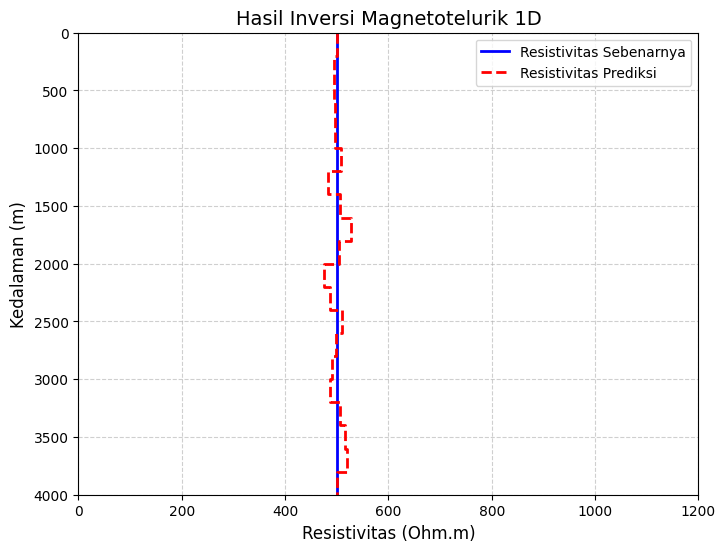

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

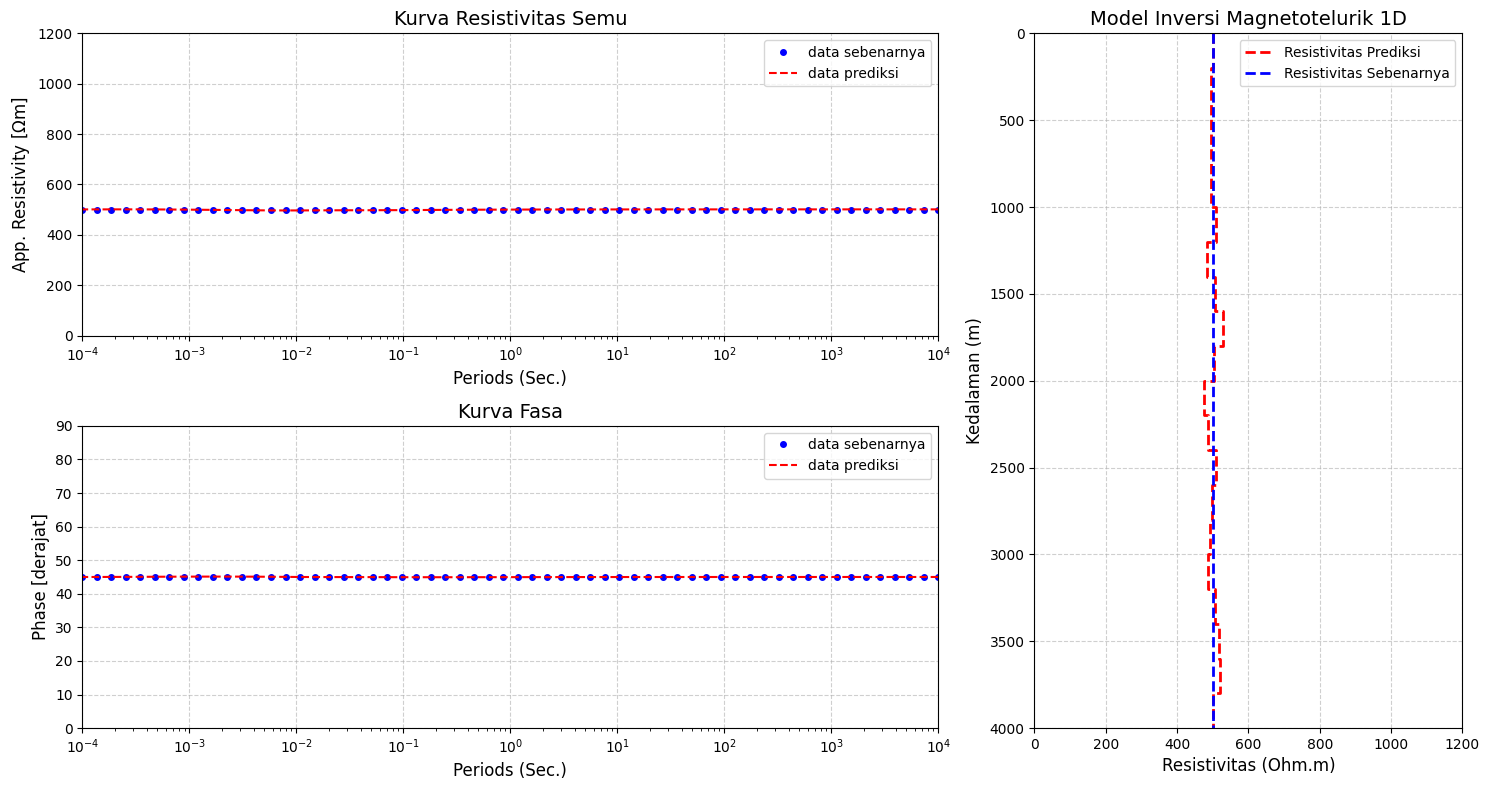

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

#Perhitungan Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 2.05
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 0.25%
MAPE fasa: 0.01%


# Prediksi Data Training

## Prediksi

In [ ]:
resis_true = y_train[0].reshape(1,-1)
resis_true = output_model_scaler.inverse_transform(resis_true)
ketebalan_true = np.full(jumlah_layer-1,layer_thickness)




resistivitas_semu = X_train_res[0].reshape(1, -1)  # Select the 201st sample and reshape to (1, 69)
fasa = X_train_phase[0].reshape(1, -1)  # Select the 201st sample and reshape to (1, 69)

# Denormalisasi data input

resistivitas_semu = input_res_scaler.inverse_transform(resistivitas_semu)
fasa = input_phase_scaler.inverse_transform(fasa)

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)


# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #Access the first 4 elements
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Nilai resis_predict [ 487.66708  471.24518  661.0882   716.4629   817.68677  763.4033
  132.8934   668.8763   841.37286  845.6202   813.4718   574.16364
  142.63803  407.2359   655.3198   627.9273   665.8495   572.86035
  784.43823 1003.20374]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


##Grafik


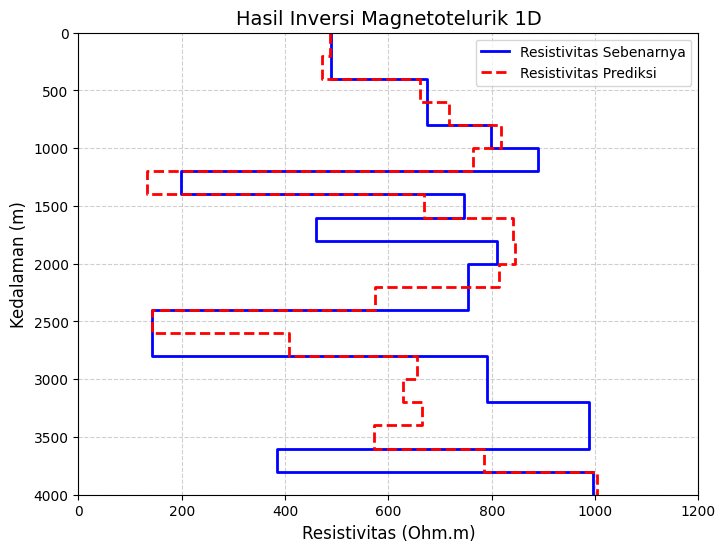

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

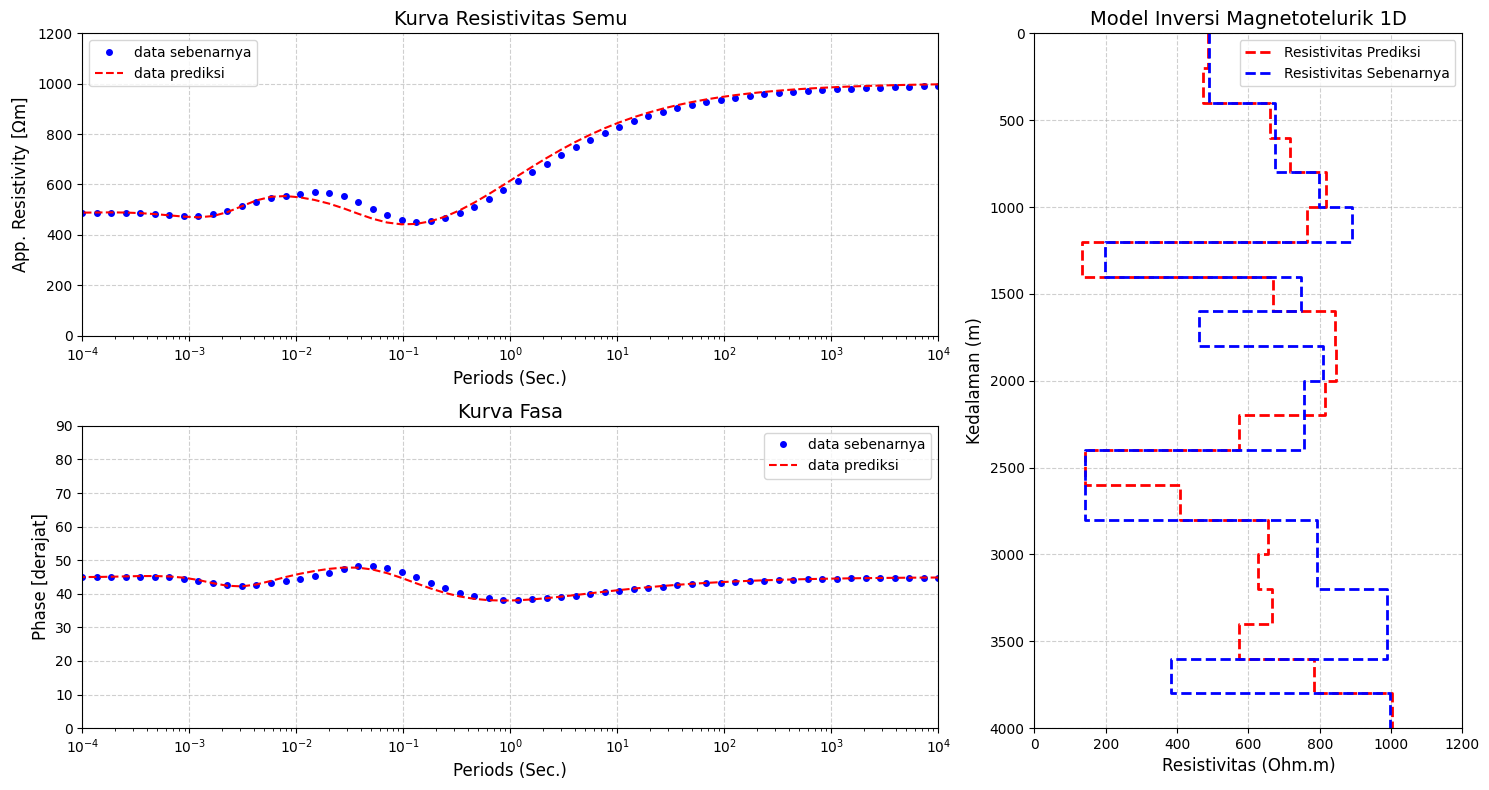

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

## Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 287.63
MSE Fasa: 0.43


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 2.01%
MAPE fasa: 0.07%


# Prediksi Data validasi

## Prediksi

In [ ]:
resis_true = y_val[0].reshape(1,-1)
resis_true = output_model_scaler.inverse_transform(resis_true)
ketebalan_true = np.full(jumlah_layer-1,layer_thickness)

resistivitas_semu = X_val_res[0].reshape(1, -1)  # Select the 201st sample and reshape to (1, 69)
fasa = X_val_phase[0].reshape(1, -1)  # Select the 201st sample and reshape to (1, 69)

# Denormalisasi data input

resistivitas_semu = input_res_scaler.inverse_transform(resistivitas_semu)
fasa = input_phase_scaler.inverse_transform(fasa)

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)


# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #Access the first 4 elements
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
Nilai resis_predict [235.73744 233.98657 231.16397 230.15678 231.7391  231.27443 233.42221
 247.9758  233.38458 221.00177 224.2009  239.94049 255.80087 244.45877
 224.8822  238.12454 327.36542 513.2594  630.15234 626.1218 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


## Grafik

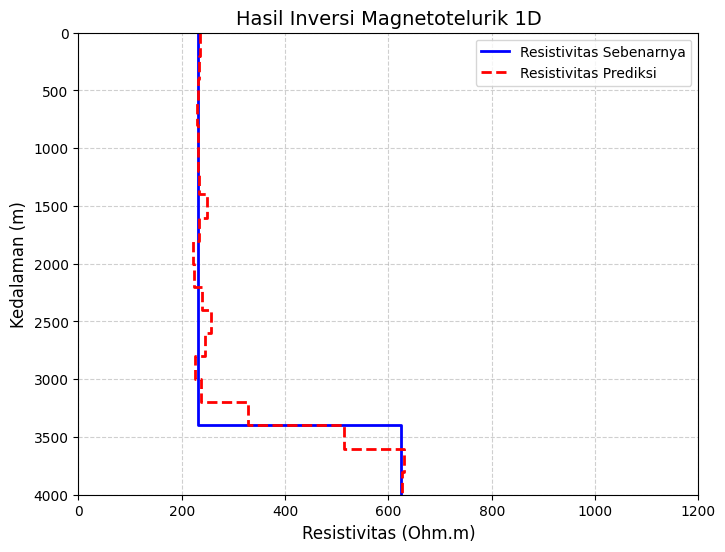

In [ ]:
plot_model_compare(resis_true,ketebalan_true,resis_predict,ketebalan_predict,total_depth)

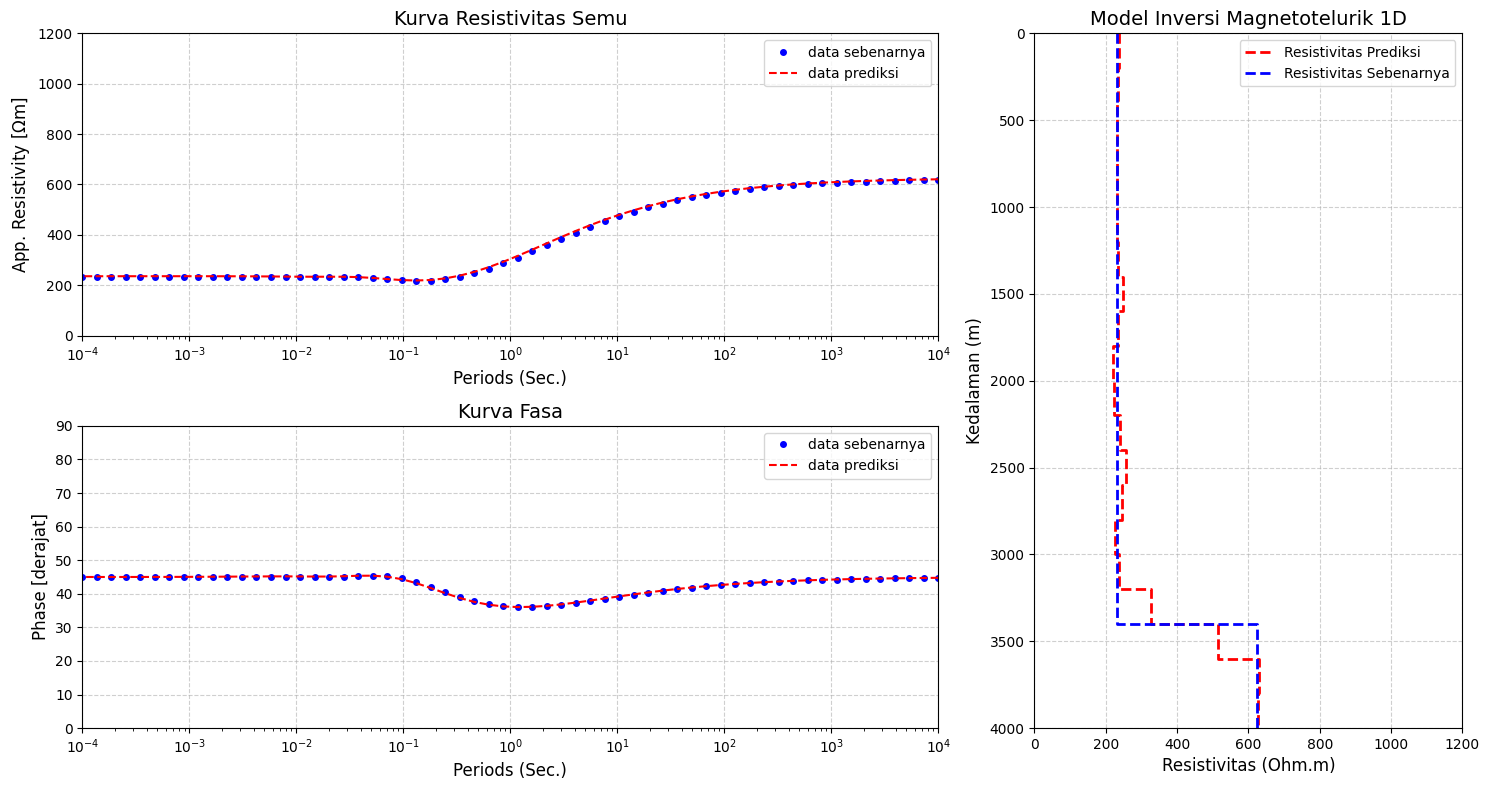

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict, resistivitas_semu_predict, total_depth)

## Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 15.05
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 1.05%
MAPE fasa: 0.03%


# Prediksi Bumi Homogen

## Model Bumi Homogen I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([100, 100])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Nilai Resis_True [100 100]
Nilai ketebalan_True [2000]
Nilai resis_predict [ 95.739555  98.36503  101.2801    93.150764 108.605644  82.61523
  87.34674   98.868675 117.63593  108.47731  102.66863   96.35578
  90.11127   89.722946  83.55312   86.999535  97.9011   117.38185
 120.22602   90.67007 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

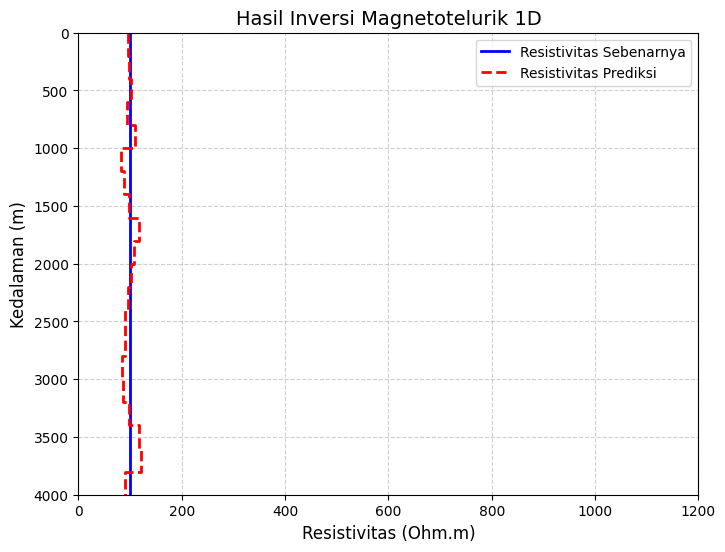

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

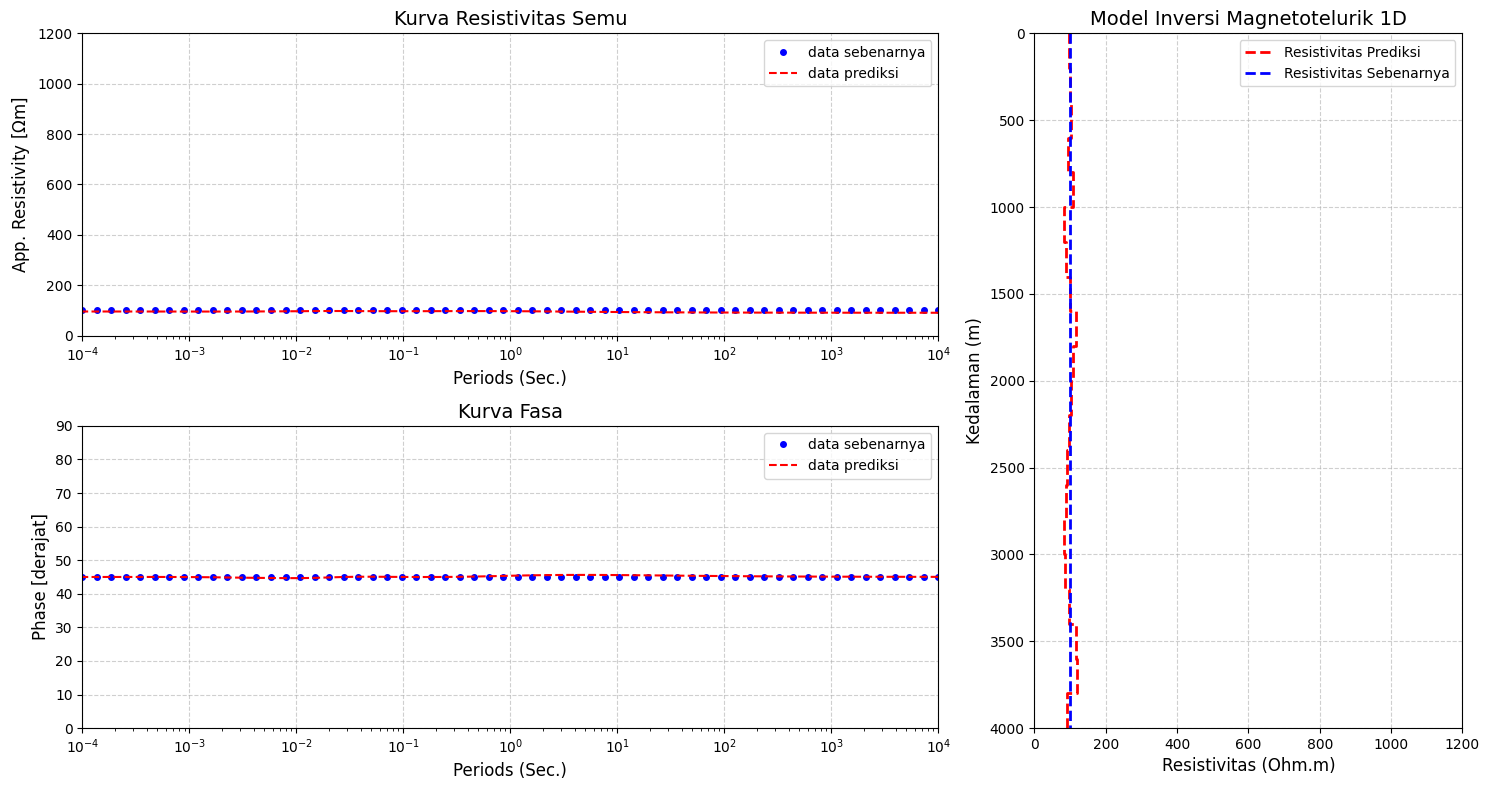

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 36.29
MSE Fasa: 0.08


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 5.49%
MAPE fasa: 0.20%


## Model Bumi Homogen II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 50])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Nilai Resis_True [50 50]
Nilai ketebalan_True [2000]
Nilai resis_predict [47.281143 50.996902 42.90124  41.049965 76.90824  49.378796 48.78055
 50.497917 61.756363 50.587948 66.67949  61.91231  58.606075 51.197777
 39.82259  49.23166  53.96841  79.02669  78.45717  42.295734]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

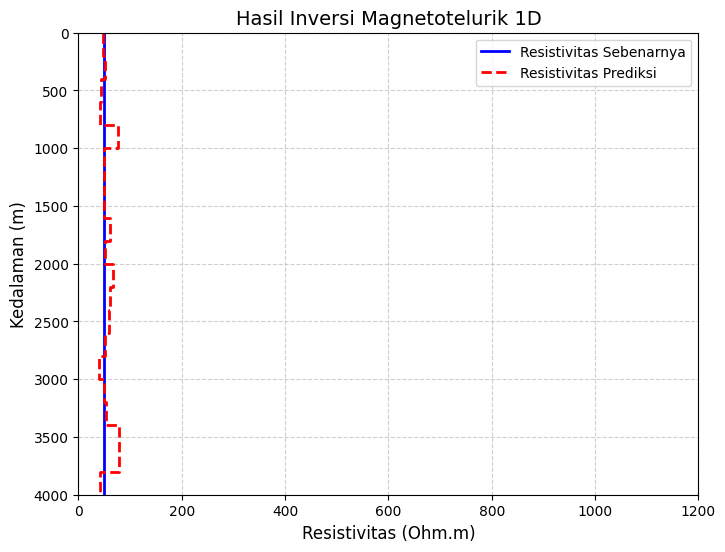

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

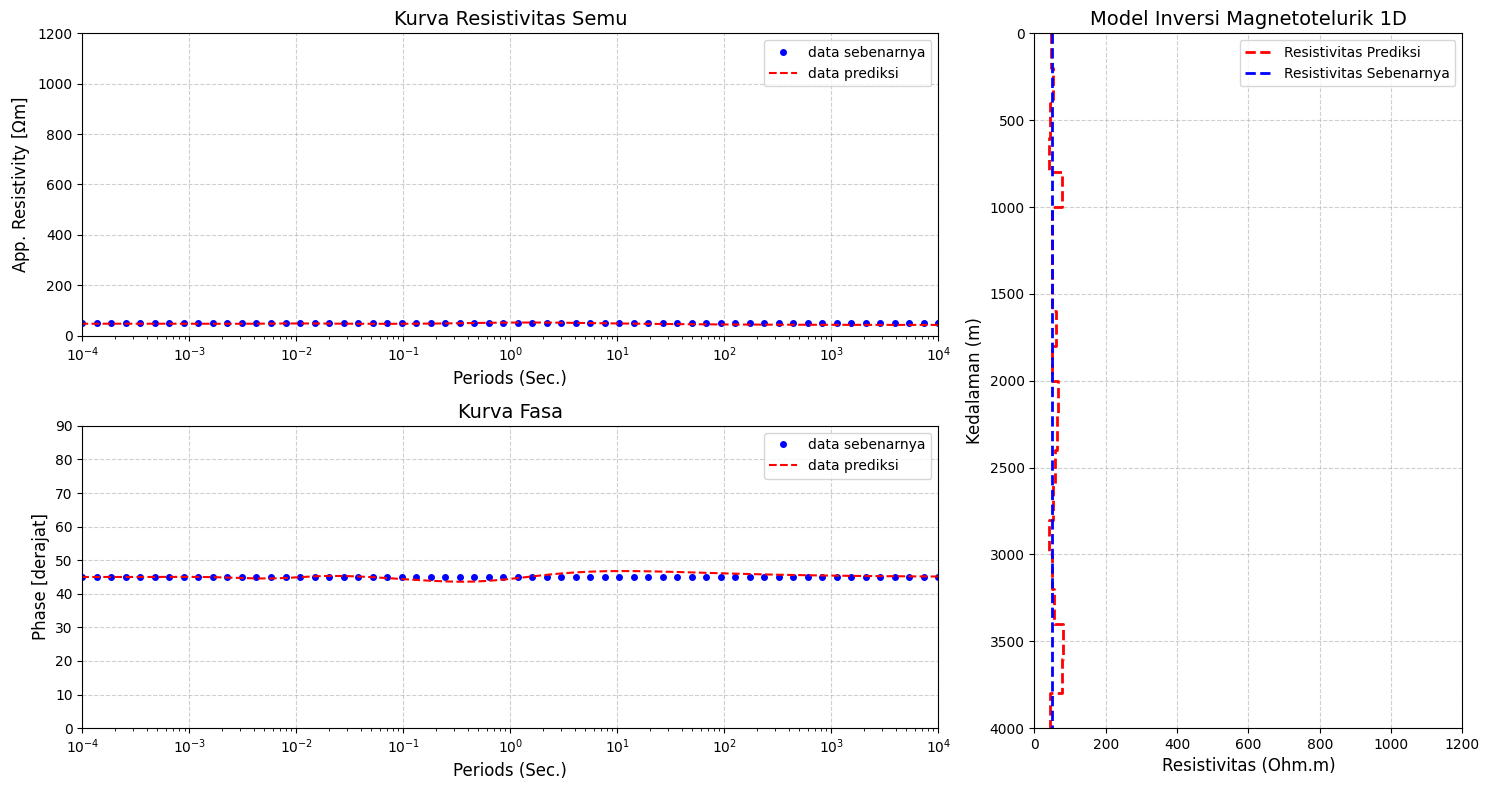

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 17.51
MSE Fasa: 0.71


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 7.12%
MAPE fasa: 1.25%


## Model Bumi Homogen III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([500, 500])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Nilai Resis_True [500 500]
Nilai ketebalan_True [2000]
Nilai resis_predict [500.8326  495.09985 494.25516 496.03485 495.68893 508.7459  483.4709
 506.77063 527.62384 504.40298 474.45233 487.5736  509.75412 499.21133
 491.43845 486.70264 506.28223 516.7857  520.3847  501.2205 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

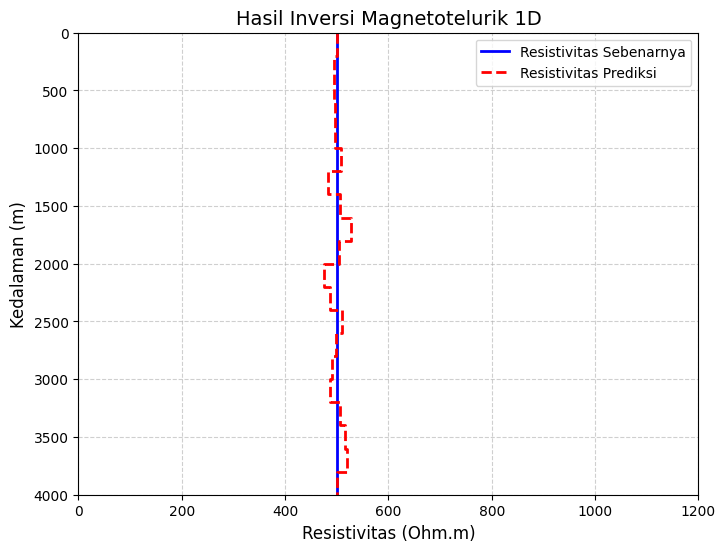

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

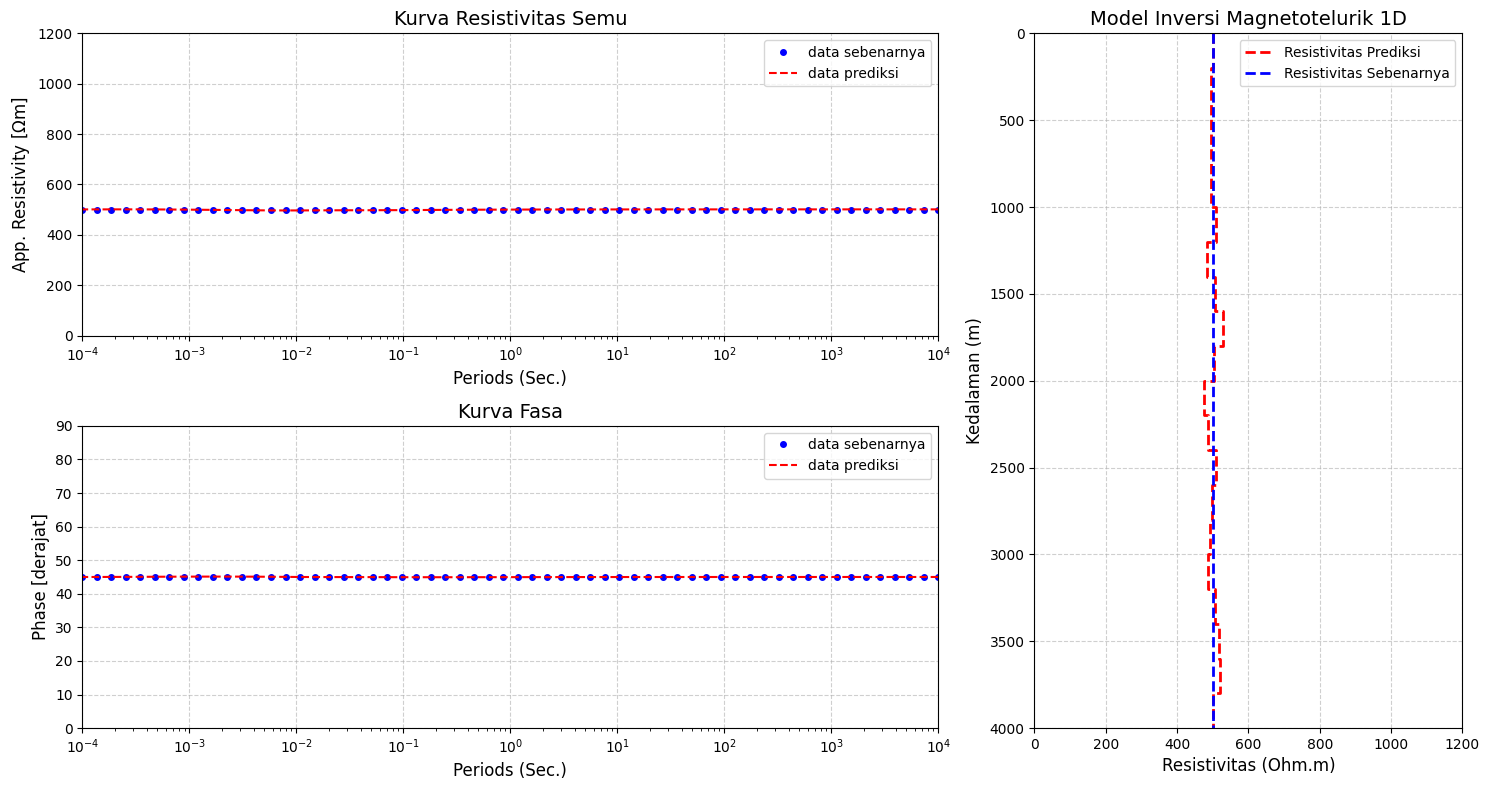

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 2.05
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 0.25%
MAPE fasa: 0.01%


# Prediksi Bumi 2 Lapis

## Model Bumi 2 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 200])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1]

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Nilai Resis_True [ 50 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 51.49199   39.476425  38.704357  31.801134  41.395863 279.62988
 315.4674   290.00732  226.68416  197.01067  126.06298  139.6739
 214.0355   219.0397   194.45493  191.97678  204.4825   203.38263
 198.88326  188.21895 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

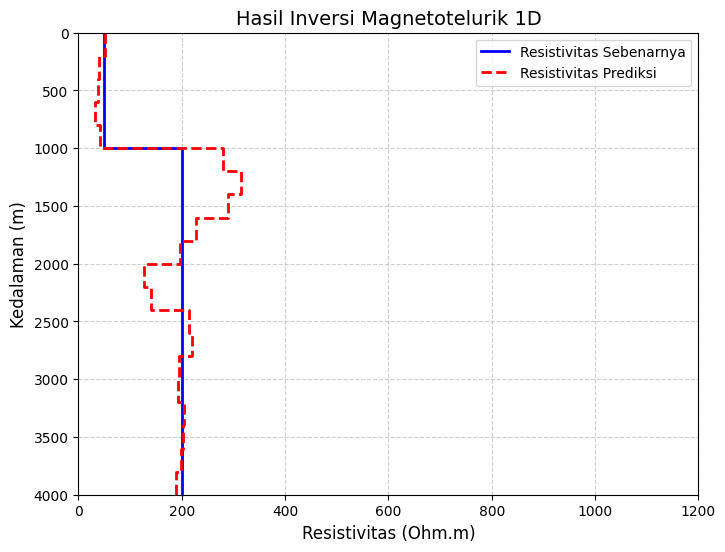

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

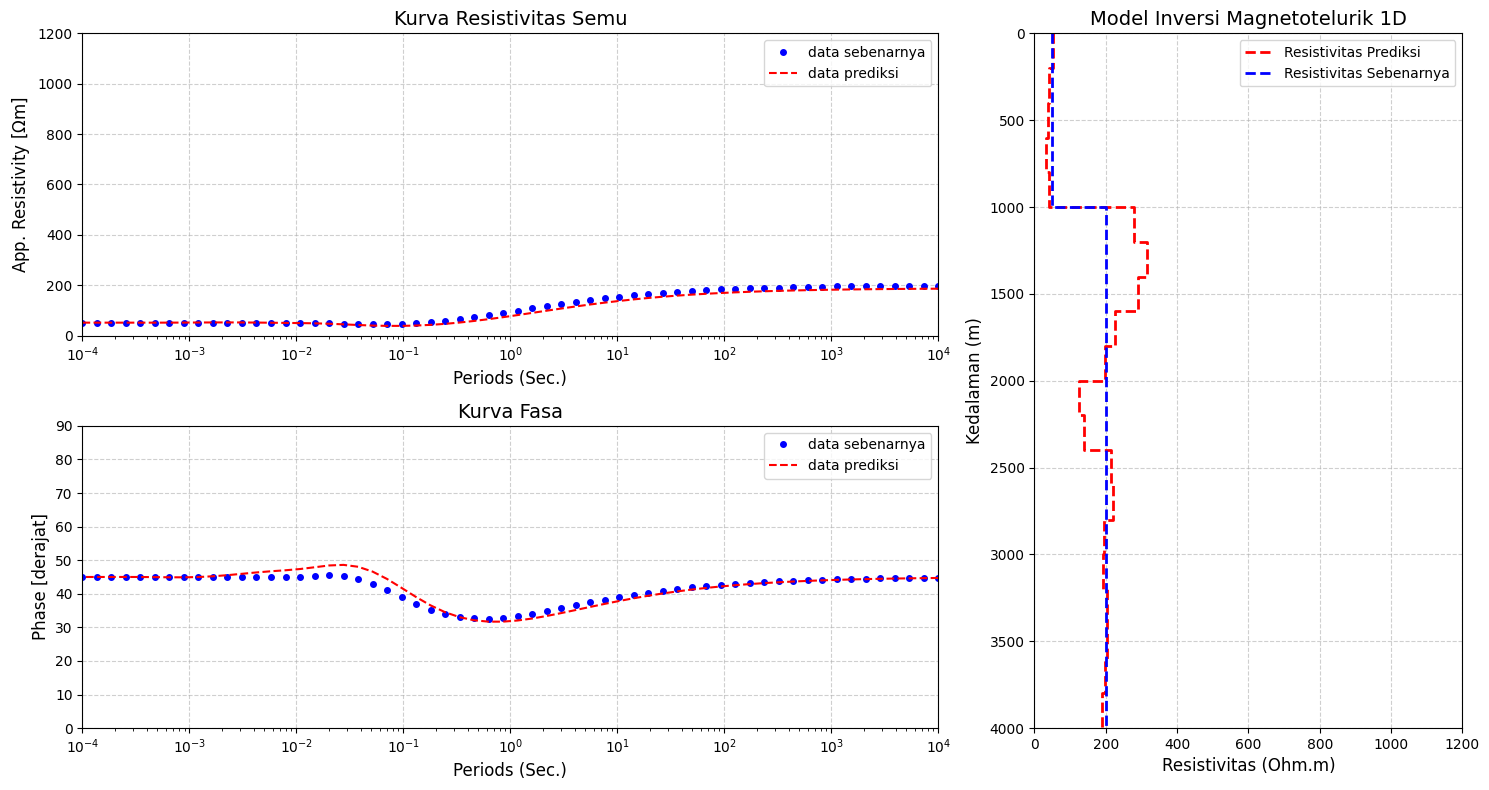

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 138.14
MSE Fasa: 1.90


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 8.98%
MAPE fasa: 1.49%


## Model Bumi 2 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 50])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Nilai Resis_True [200  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [201.58989   193.9467    188.39787   210.96194   190.21805    57.88558
   1.9372389  64.04394    71.85431    49.019413   57.41327    48.60733
  24.608328   32.022907   36.1411     40.196117   55.321926   73.082245
  74.90832    42.875168 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

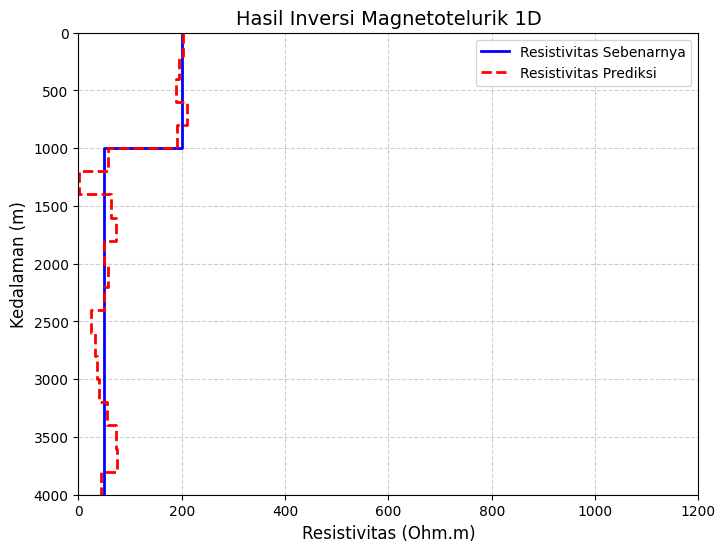

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

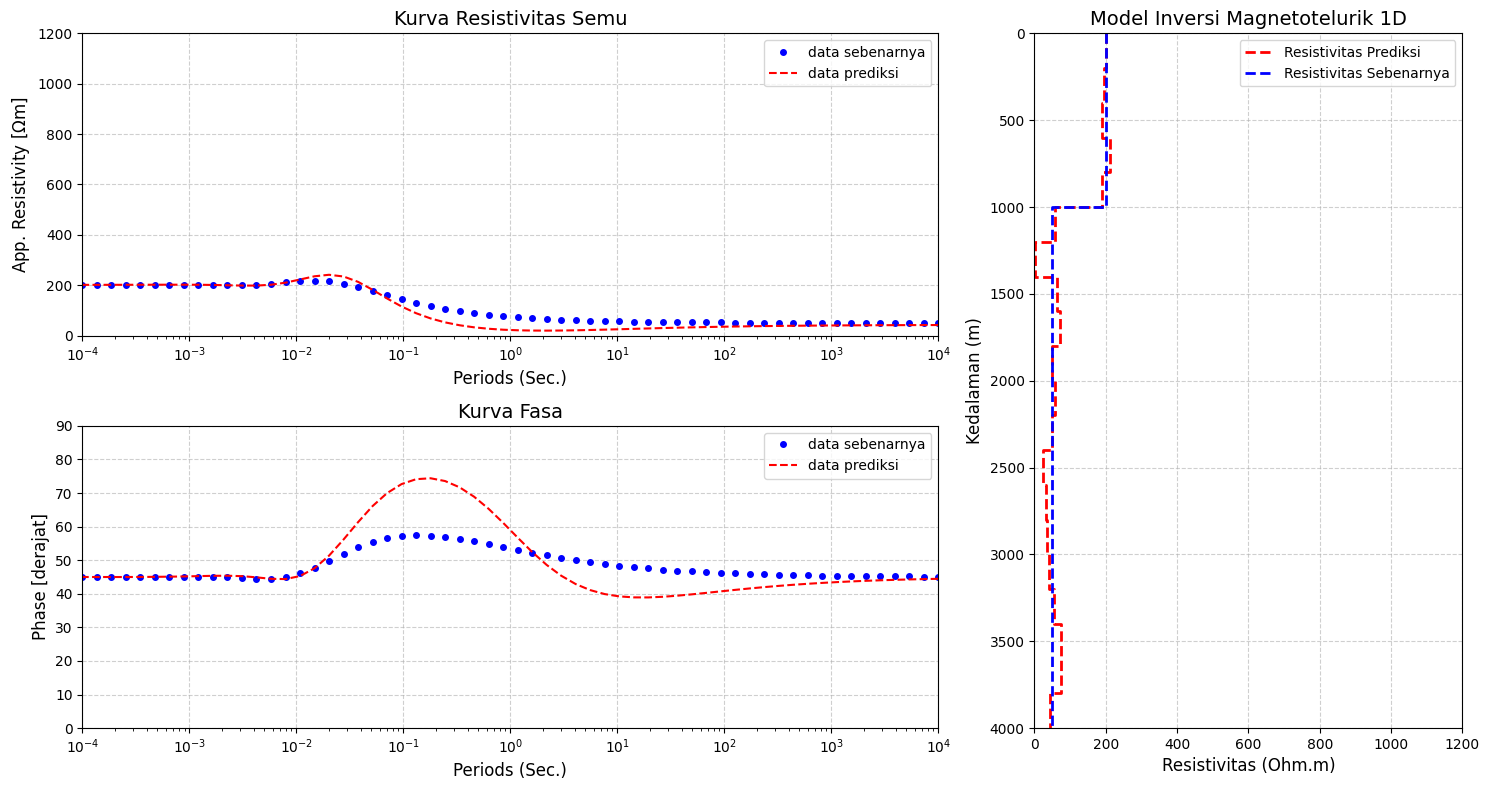

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 702.42
MSE Fasa: 47.66


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 26.77%
MAPE fasa: 6.10%


## Model Bumi 2 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50,800])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Nilai Resis_True [ 50 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [ 62.909813  41.72544   34.05951   31.107714  63.516544 753.21954
 777.73517  839.466    888.4106   879.969    888.5405   868.758
 846.98224  826.04443  812.39404  820.1477   803.5438   797.80994
 787.853    785.95795 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

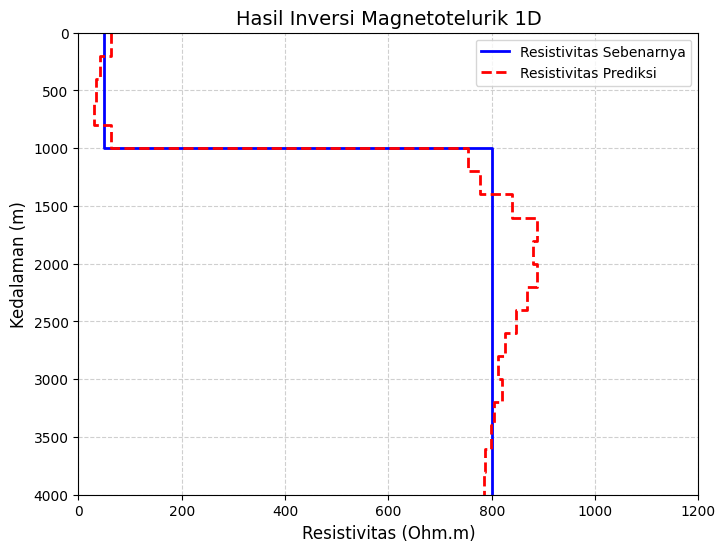

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

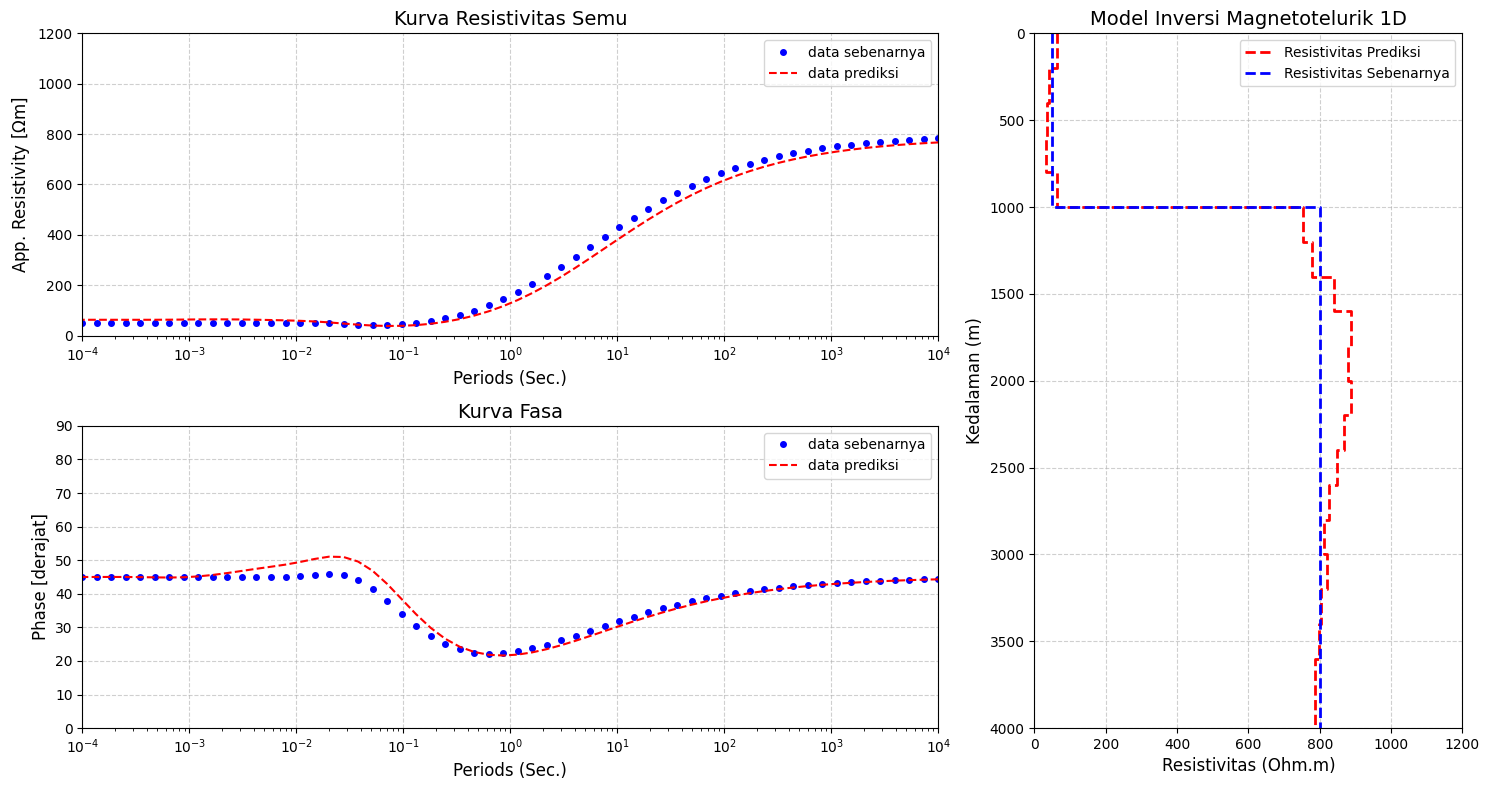

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MSE Resistivitas Semu: 601.40
MSE Fasa: 4.67


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 13.53%
MAPE fasa: 2.24%


## Model Bumi 2 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 50])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Nilai Resis_True [800  50]
Nilai ketebalan_True [1000]
Nilai resis_predict [803.5969   812.6314   816.20685  820.3351   810.39044   39.661343
  60.030453  80.48792   66.90195   73.385544  78.04675   56.416485
  35.59891   29.956991  34.131275  50.848843  68.2694    82.118385
  84.18097   24.963245]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

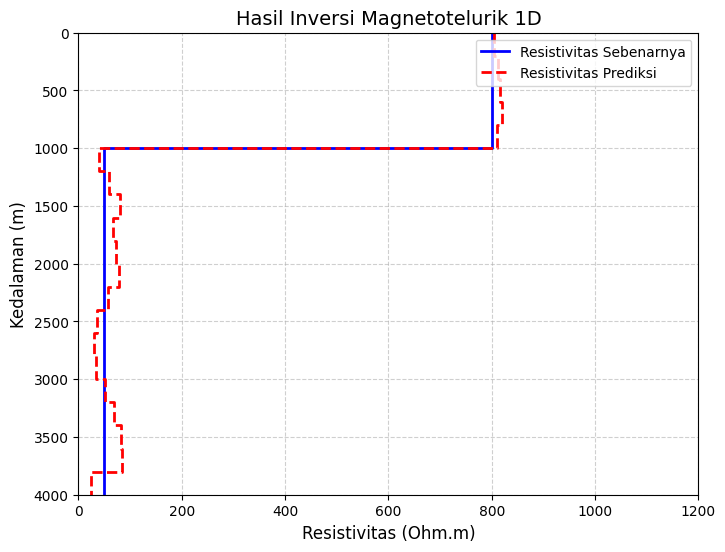

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

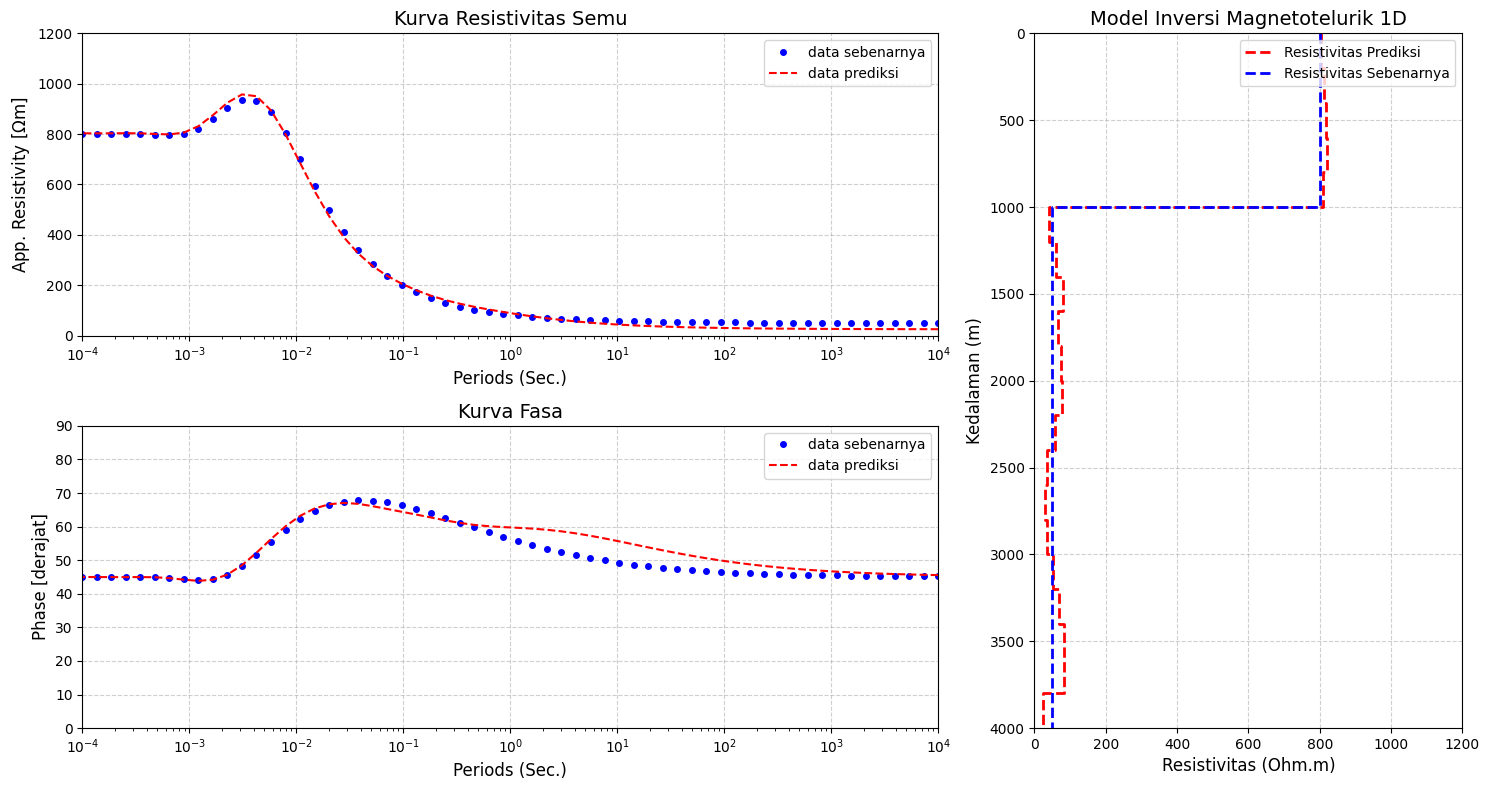

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 274.83
MSE Fasa: 8.49


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MAPE resistivitas semu: 19.39%
MAPE fasa: 3.04%


## Model Bumi 2 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Nilai Resis_True [200 800]
Nilai ketebalan_True [1000]
Nilai resis_predict [199.09688 204.98264 202.48619 196.71951 214.27068 787.49    809.0423
 822.32294 836.07324 816.061   811.1877  794.98724 810.1167  799.3378
 796.2364  819.62787 825.9908  805.77765 815.7369  807.8841 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

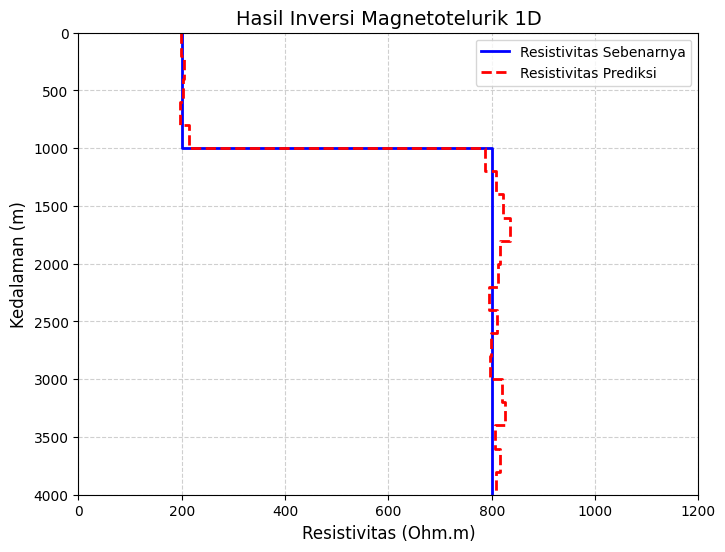

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


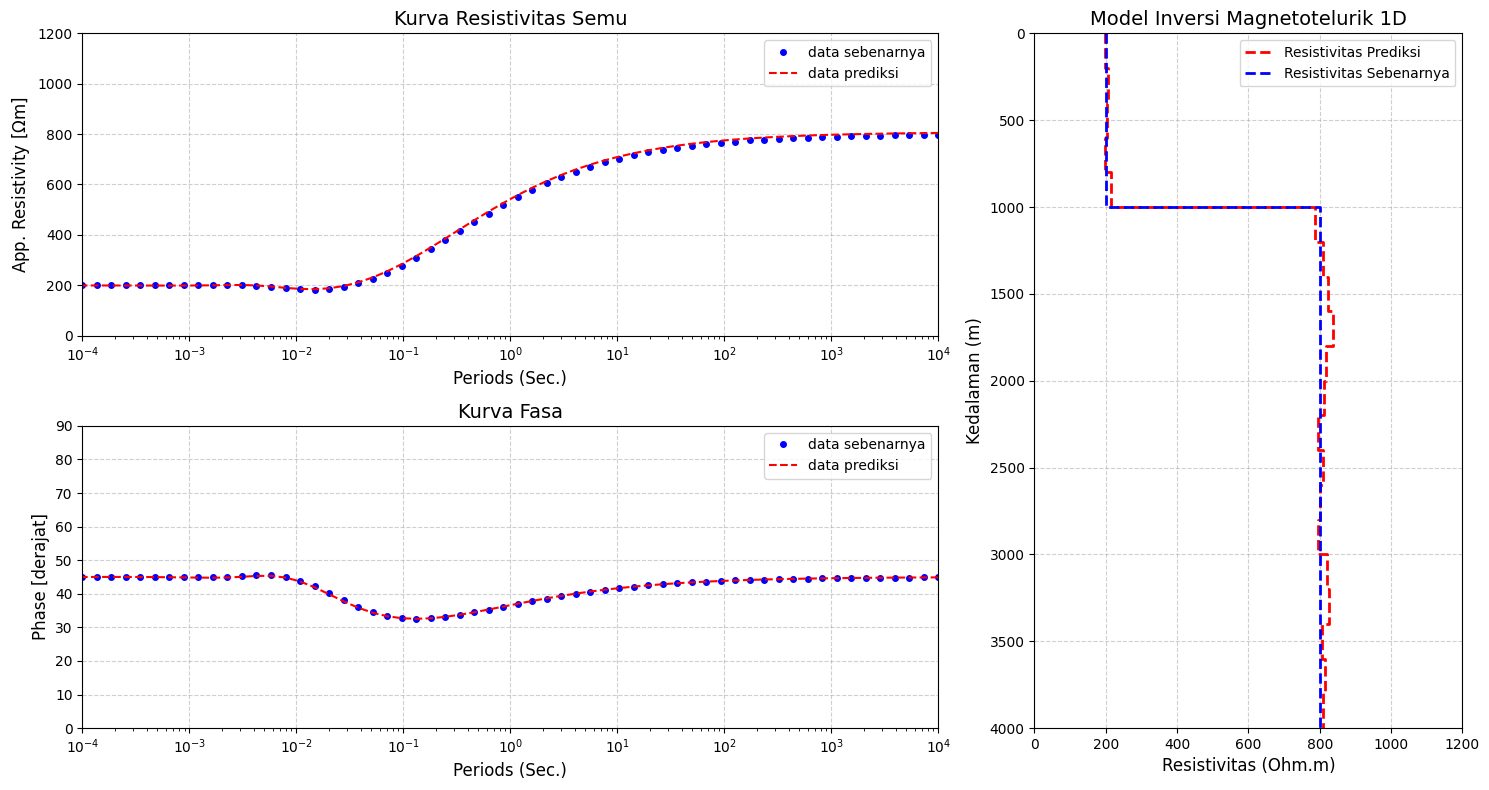

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])


MSE Resistivitas Semu: 42.24
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu[0], fasa[0], resistivitas_semu_predict[0], fasa_predict[0])

MAPE resistivitas semu: 1.07%
MAPE fasa: 0.03%


## Model Bumi 2 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 200])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Nilai Resis_True [800 200]
Nilai ketebalan_True [1000]
Nilai resis_predict [798.086   789.3026  798.2827  817.72375 800.14075 197.67613 201.36954
 229.35255 211.94962 194.9772  208.54727 187.97285 189.65575 186.61528
 202.67691 214.05788 210.6342  190.4625  204.37936 198.81589]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

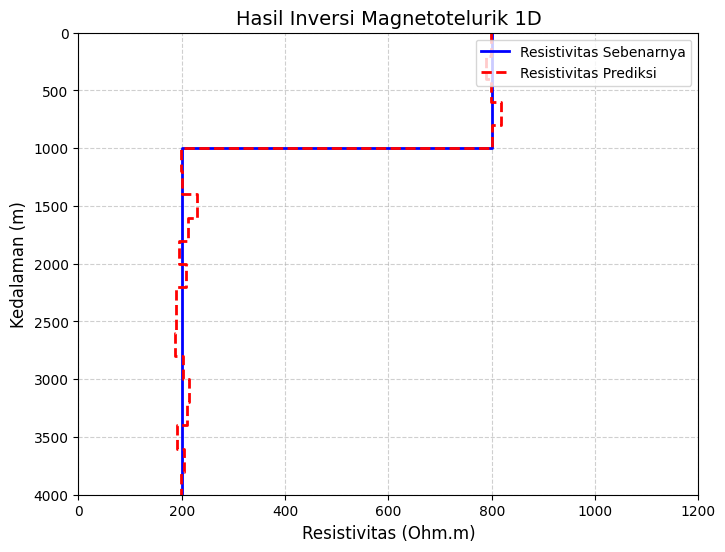

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

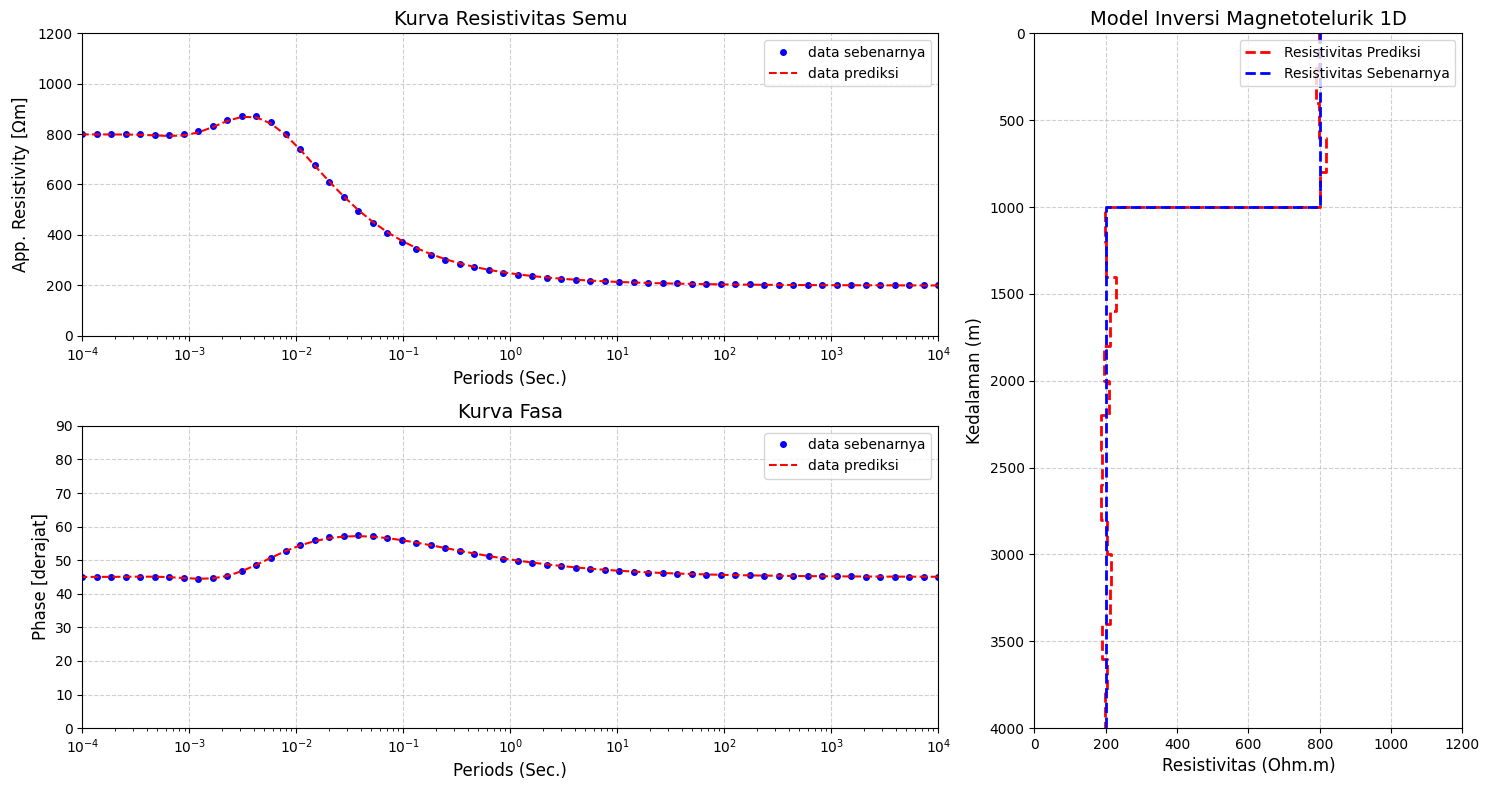

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 7.50
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.52%
MAPE fasa: 0.02%


# Prediksi Bumi 3 Lapis

## Model Bumi 3 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 200, 800])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Nilai Resis_True [ 50 200 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [  75.55015   67.16559 1275.4408   172.56613  142.86435  323.92126
  406.04507  684.6845   763.49225  801.2504   844.6096   882.1062
  883.4063   877.659    876.2591   869.18414  857.1746   826.26306
  801.9051   784.55865]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

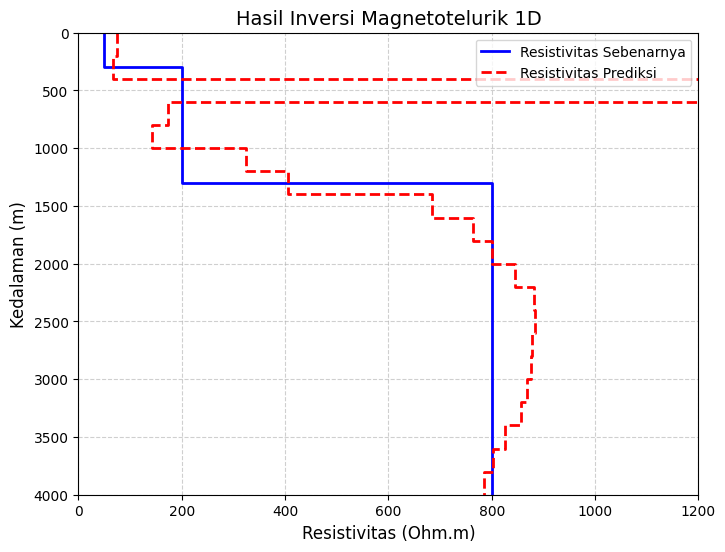

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

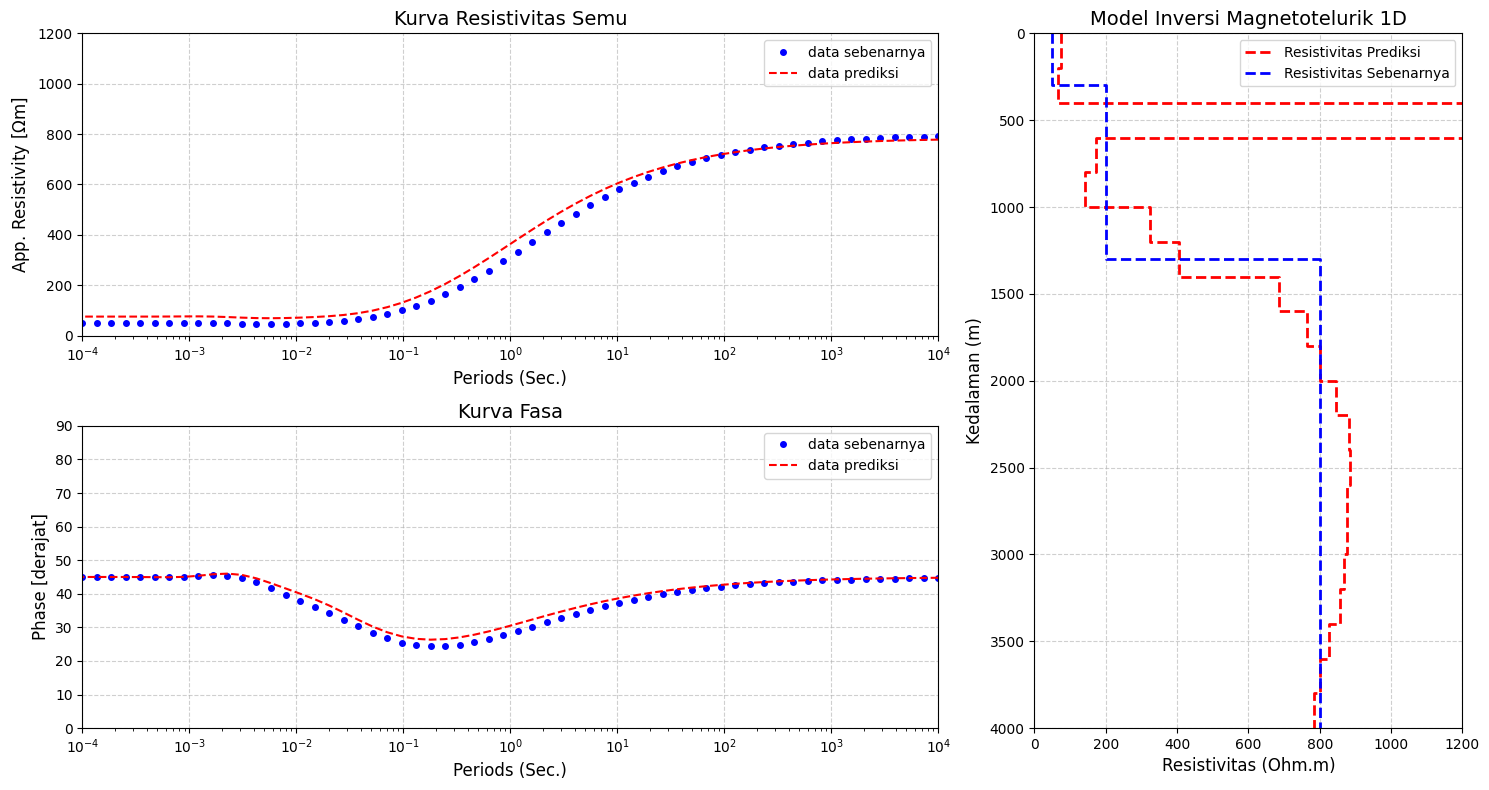

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 737.33
MSE Fasa: 1.83


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 22.20%
MAPE fasa: 0.88%


## Model Bumi 3 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 800, 200])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Nilai Resis_True [ 50 800 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 168.78952  104.48334 1596.9509   857.26447  555.86896  640.9617
  454.9955   335.76804  105.48321  268.04794  273.60028  247.5292
  232.90051  229.93704  246.82622  224.26329  182.35388  125.45872
  136.46011  150.06961]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

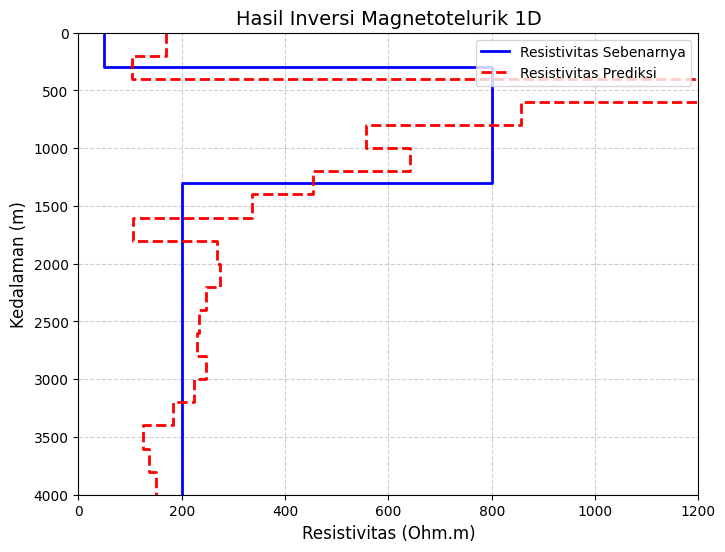

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

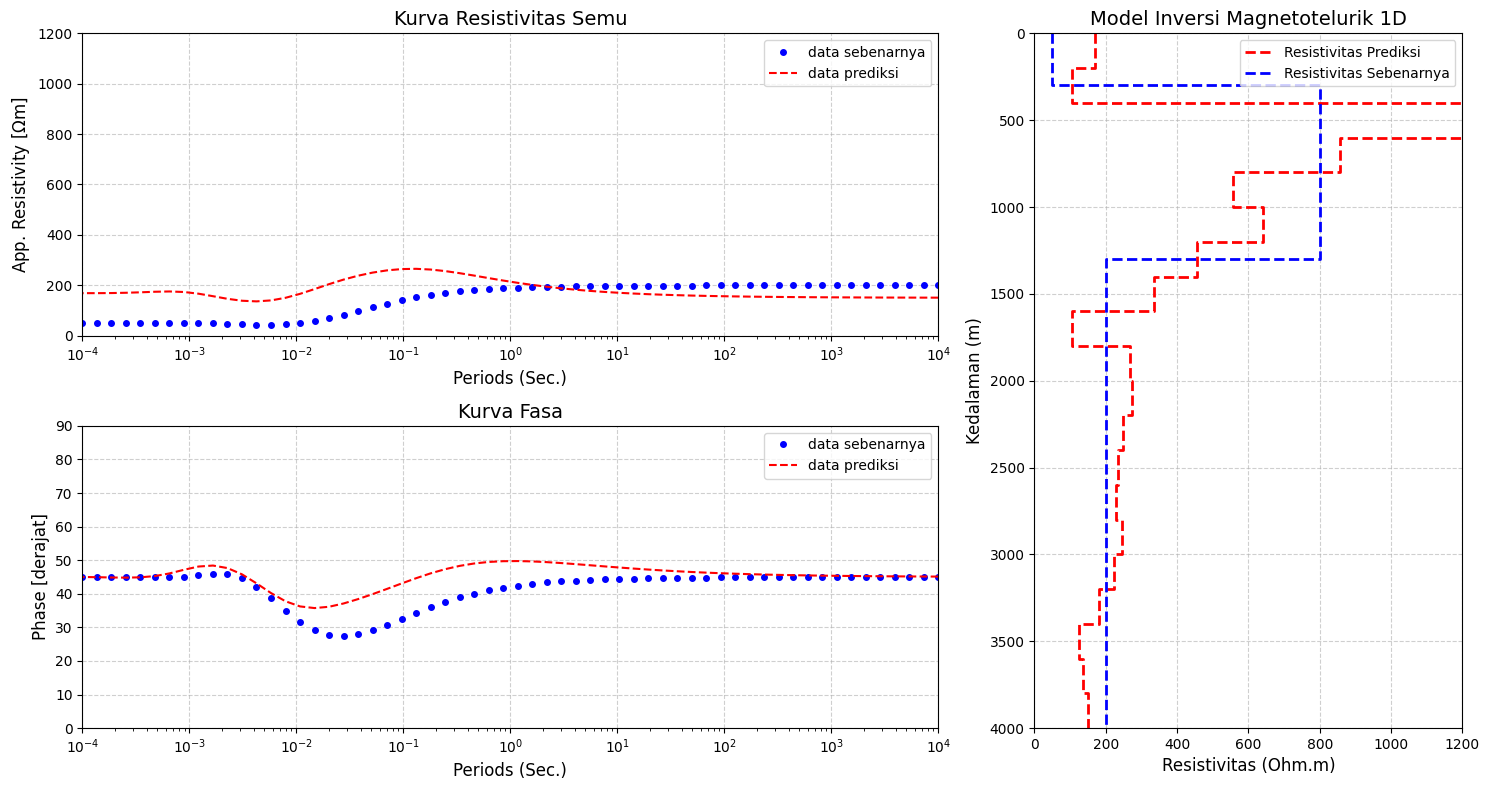

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 6943.43
MSE Fasa: 26.46


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 93.26%
MAPE fasa: 3.12%


## Model Bumi 3 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 50, 800])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Nilai Resis_True [200  50 800]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [221.05652  109.20465   40.86583   80.4447    23.855633  63.14076
 345.91714  837.7331   786.6624   815.34344  824.20435  857.3035
 827.50073  831.1536   856.07227  826.822    813.50616  810.26416
 818.74603  806.9159  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

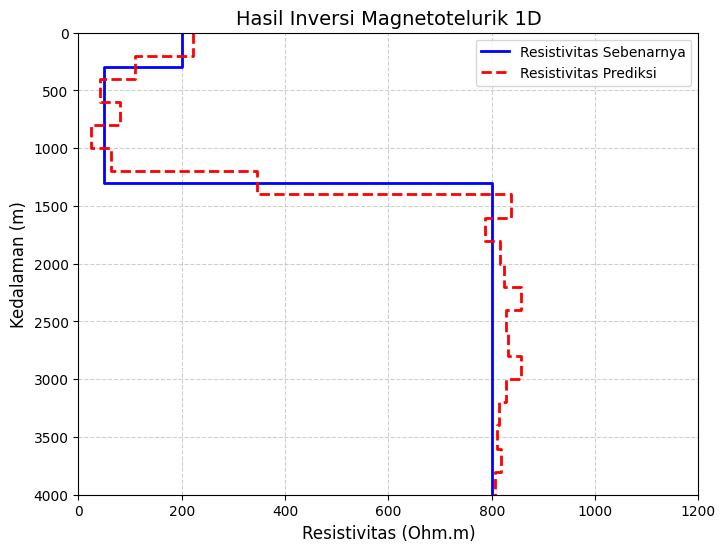

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

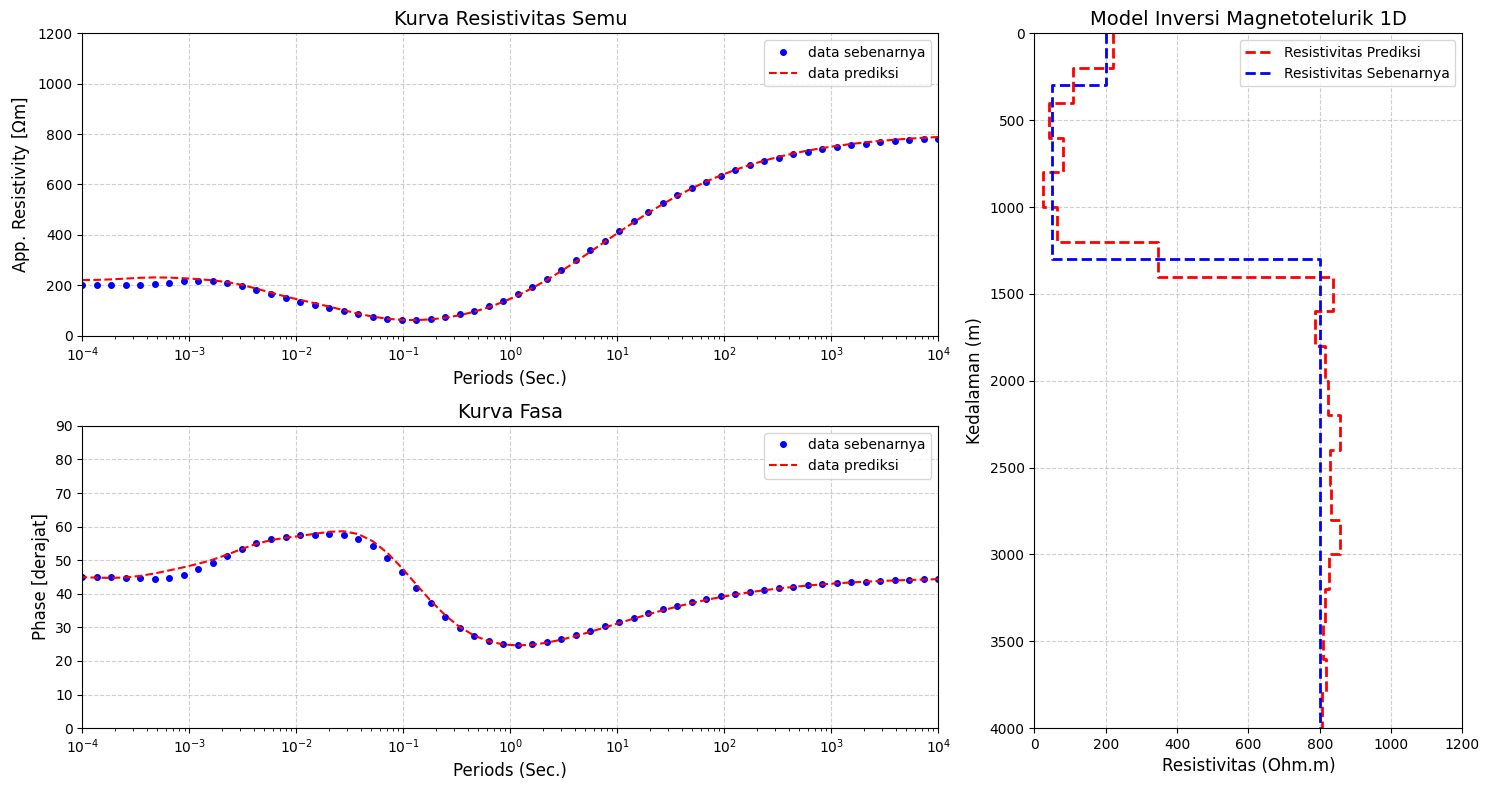

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 89.92
MSE Fasa: 0.53


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.23%
MAPE fasa: 0.36%


## Model Bumi 3 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([200, 800, 50])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
Nilai Resis_True [200 800  50]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [ 229.47754   281.35687  1327.9812    603.7745    690.88074   885.16
  362.1943     14.370898  102.56705    66.39653    63.204082   28.664446
  -31.18862   -17.201906   57.155556   83.32495    64.55677    44.423874
   51.46938    27.711725]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

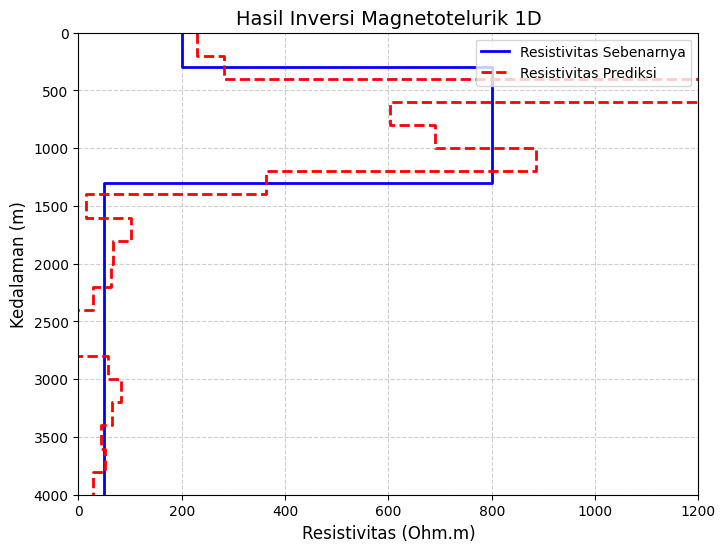

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

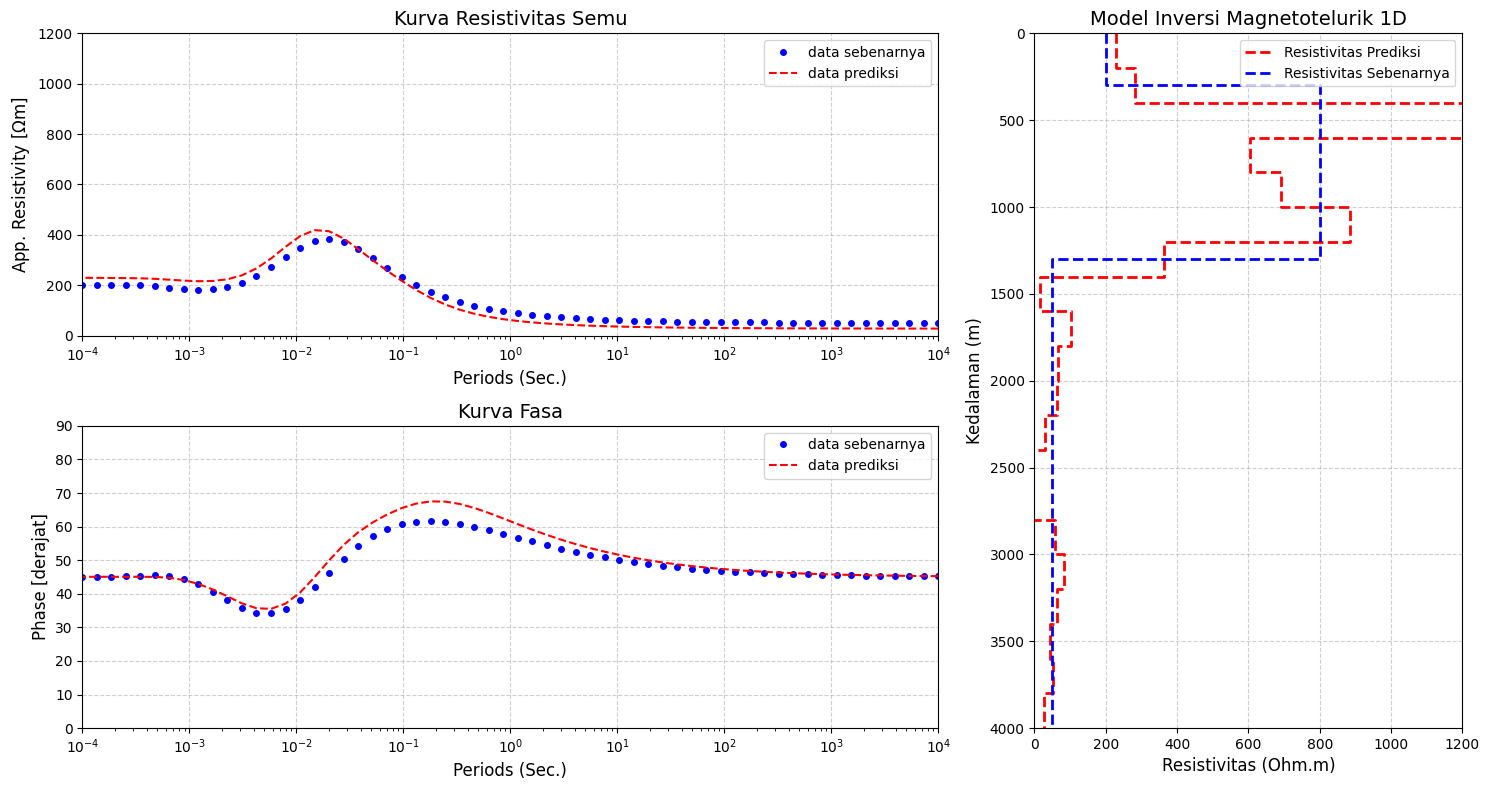

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 738.98
MSE Fasa: 6.81


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 28.39%
MAPE fasa: 1.46%


## Model Bumi 3 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([800, 50, 200])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
Nilai Resis_True [800  50 200]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [907.8433   405.07047   70.82961   58.54514   42.679577  39.84888
 179.59445  304.97742  326.951    304.5717   245.33348  227.4714
 219.02931  189.92813  152.61084  174.90765  244.23773  277.1883
 278.44302  188.6975  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

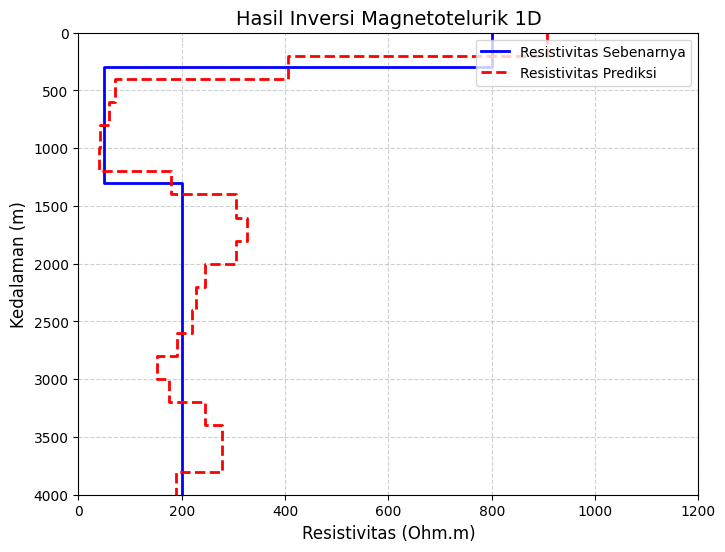

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


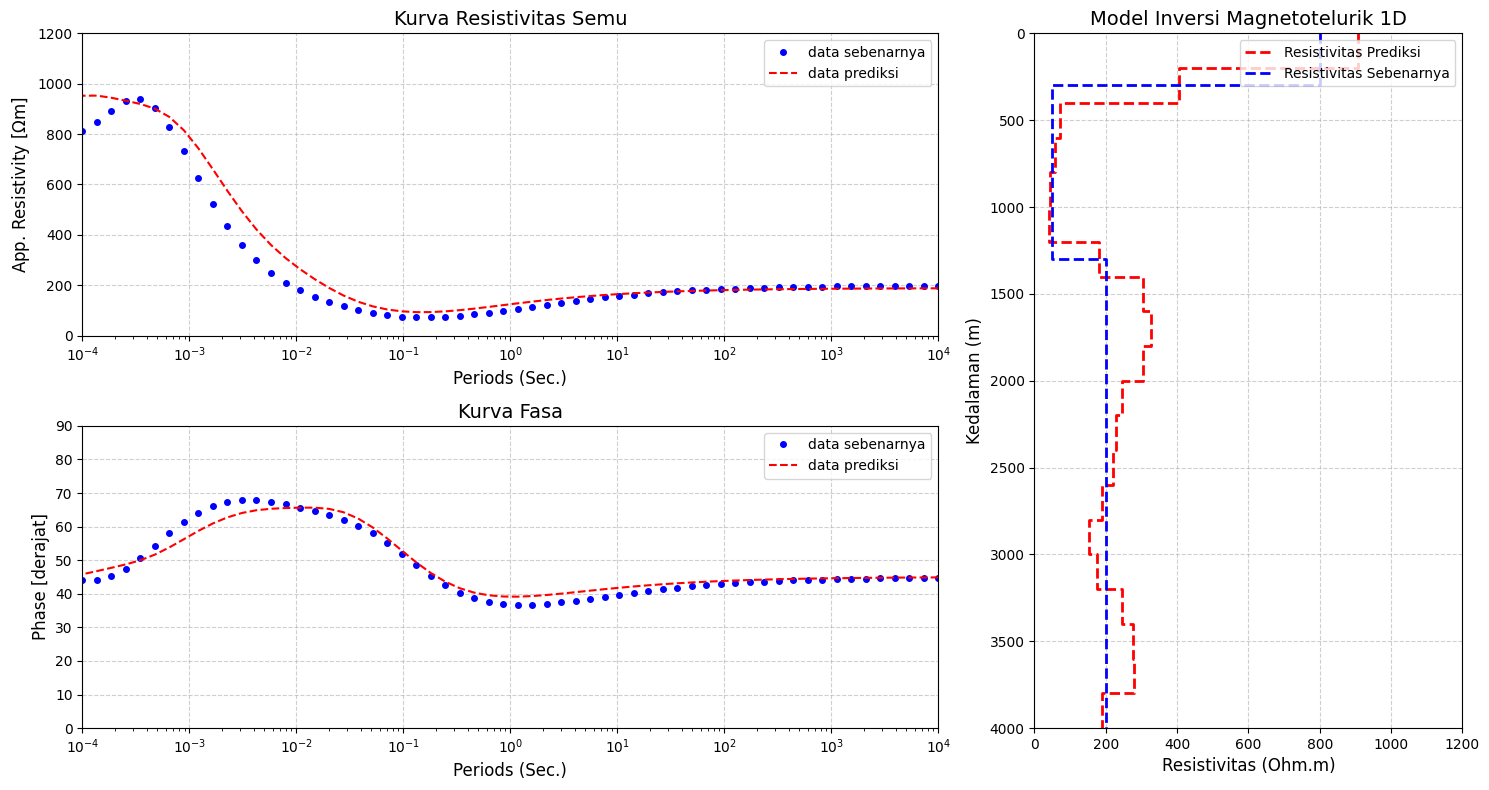

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 2895.34
MSE Fasa: 4.51


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 15.65%
MAPE fasa: 0.91%


## Model Bumi 3 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 800, 200, 50])
ketebalan_true = np.array([300,1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Nilai Resis_True [800 200  50]
Nilai ketebalan_True [ 300 1000]
Nilai resis_predict [869.89465  449.39813  139.21985  292.53342  207.37566  226.62325
 185.81131  -10.542731  93.72395   84.10671   56.737133  56.988235
  91.455315 107.113014  89.83596   59.067726  36.201954  66.052956
  81.89214   26.704939]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

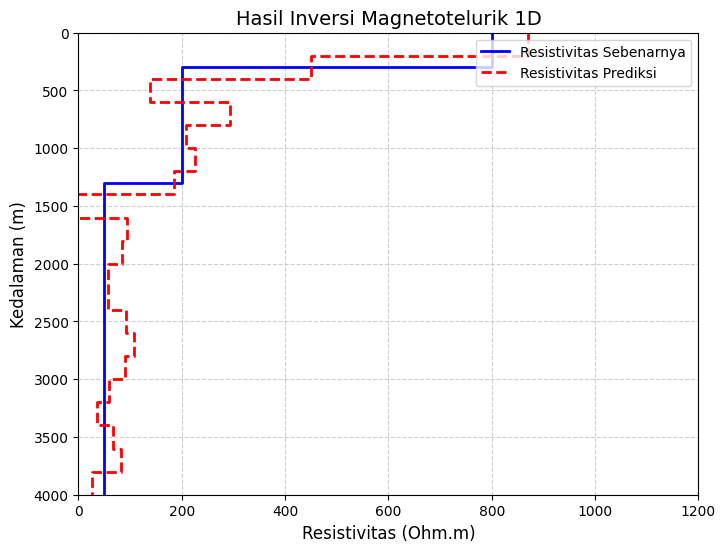

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

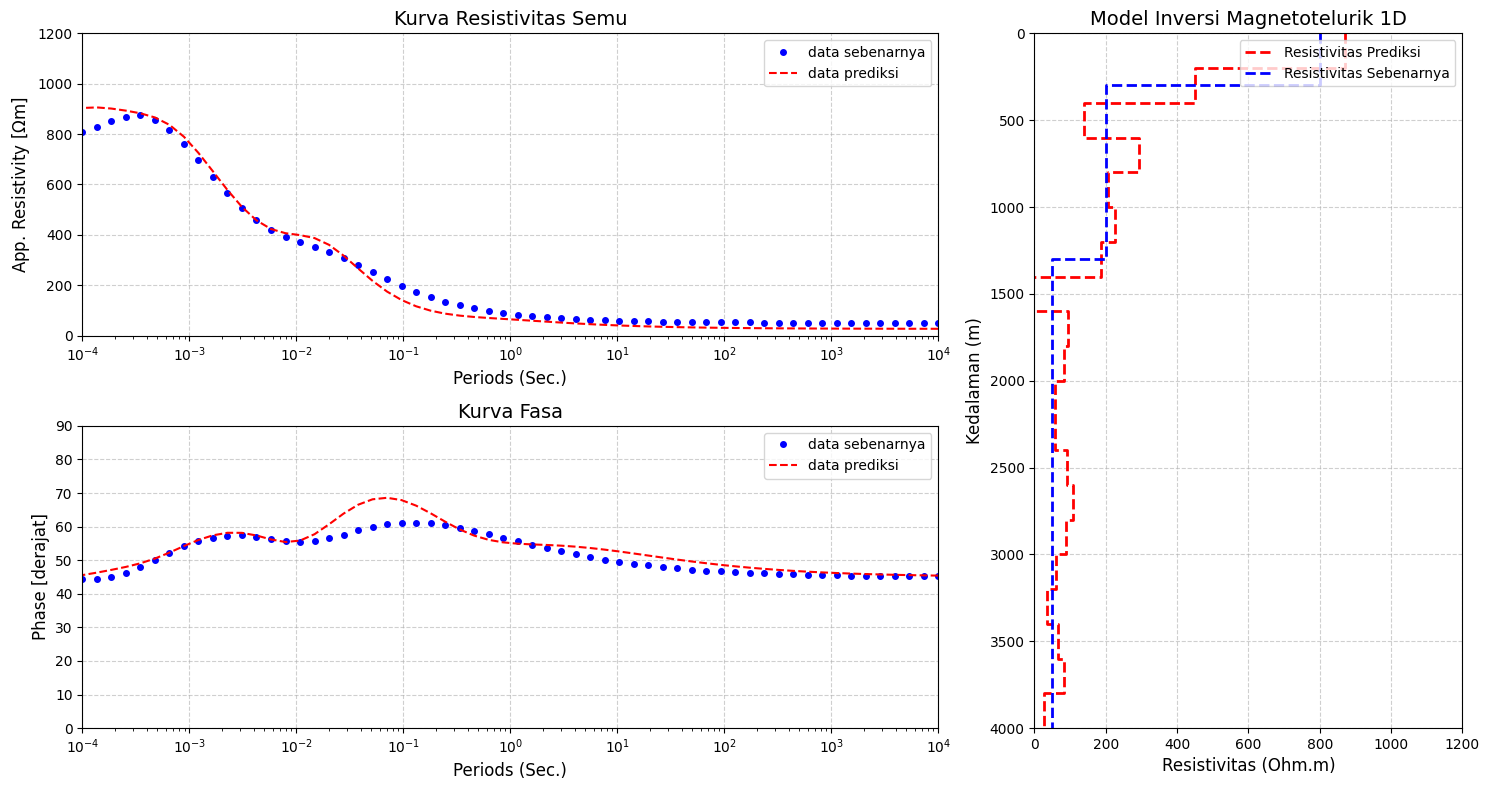

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 965.12
MSE Fasa: 7.42


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 25.55%
MAPE fasa: 1.79%


# Prediksi Bumi 4 Lapis

## Model Bumi 4 Lapis I

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 50, 200, 800, 1000])
ketebalan_true = np.array([200,500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
Nilai Resis_True [  50  200  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [  52.078033  171.7114    234.17447   565.8539    742.8571    850.3729
  803.2215    863.485     910.5258    890.8462    934.9504    969.88715
  973.8555   1000.715    1054.7985   1058.3403   1034.9438   1026.1582
 1011.81946   977.7233  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

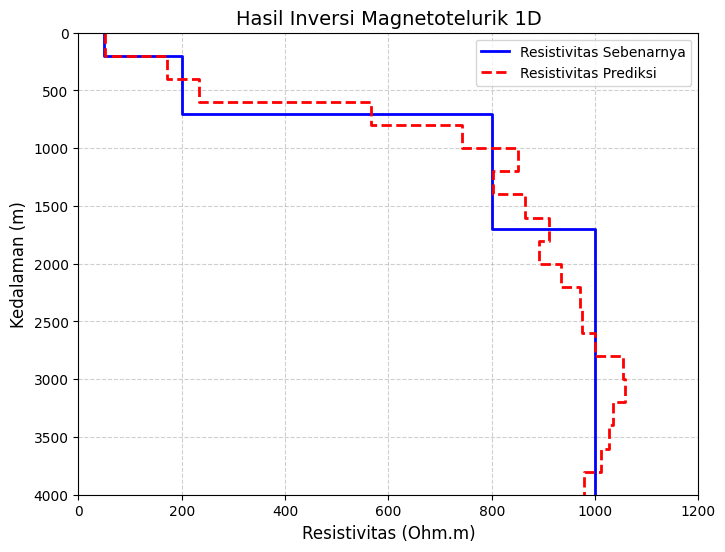

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

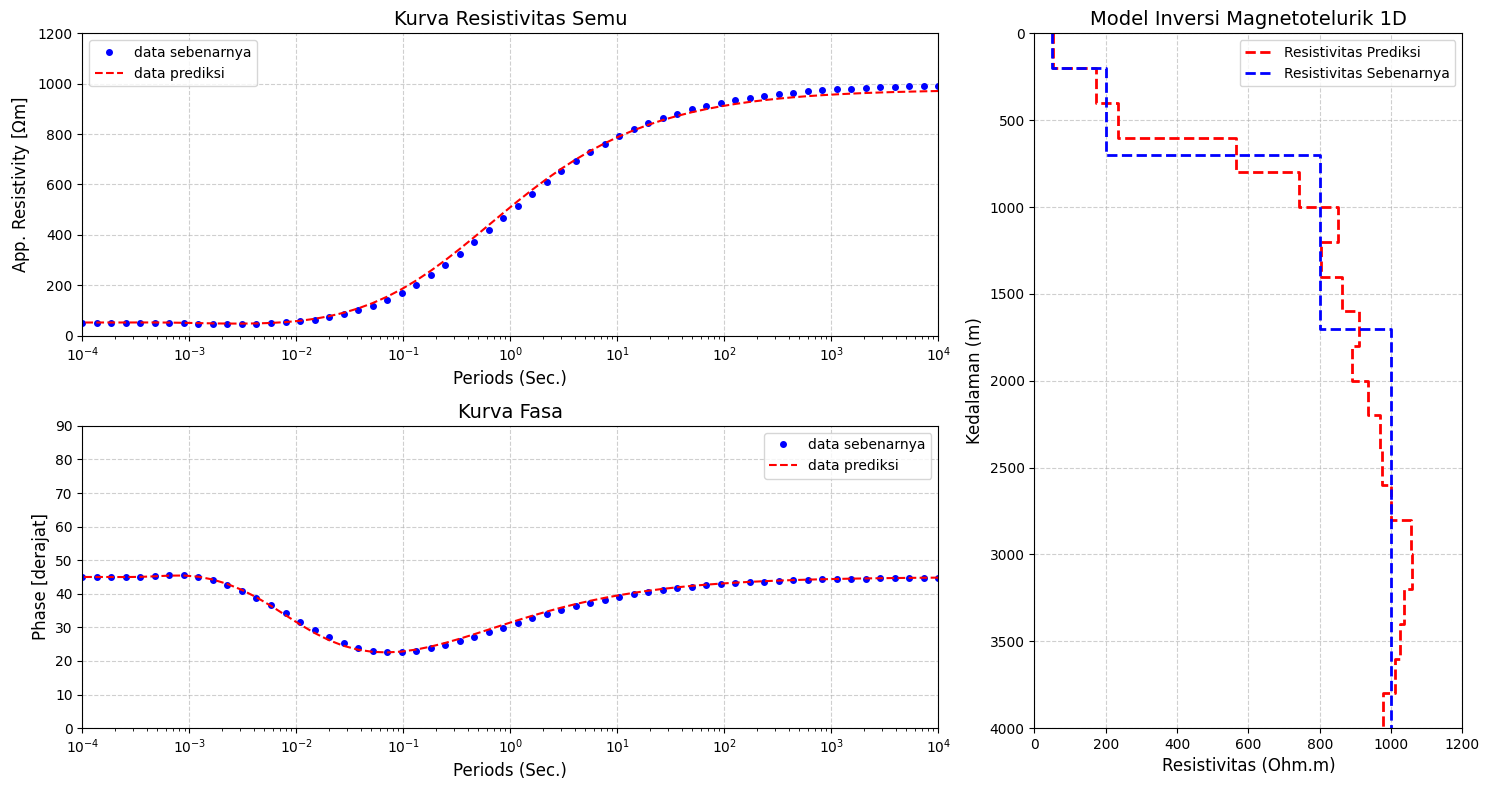

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 170.77
MSE Fasa: 0.18


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 3.37%
MAPE fasa: 0.20%


## Model Bumi 4 Lapis II

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 800, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Nilai Resis_True [  50  800  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [  60.878372  750.9584    766.1108    351.64938   241.55855   235.6164
  167.25214   282.0321    527.03204   915.1547    920.04663   956.9713
  964.2593    979.8714   1013.9488    977.8746    953.41785   918.10815
  865.8621    971.10266 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

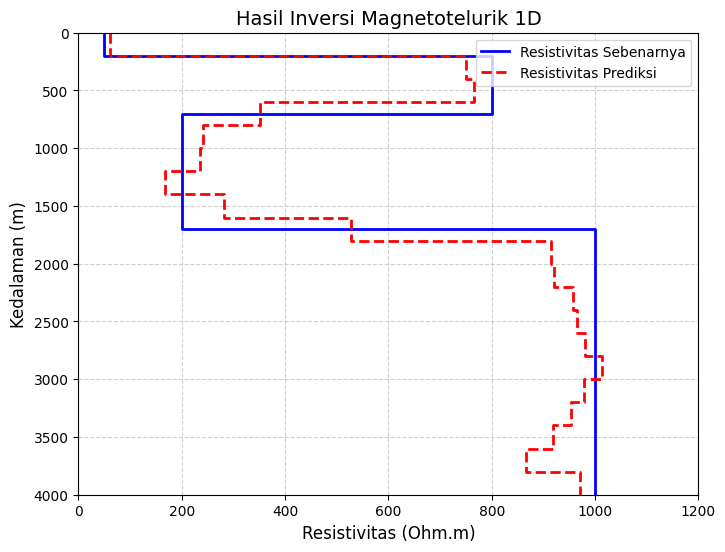

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

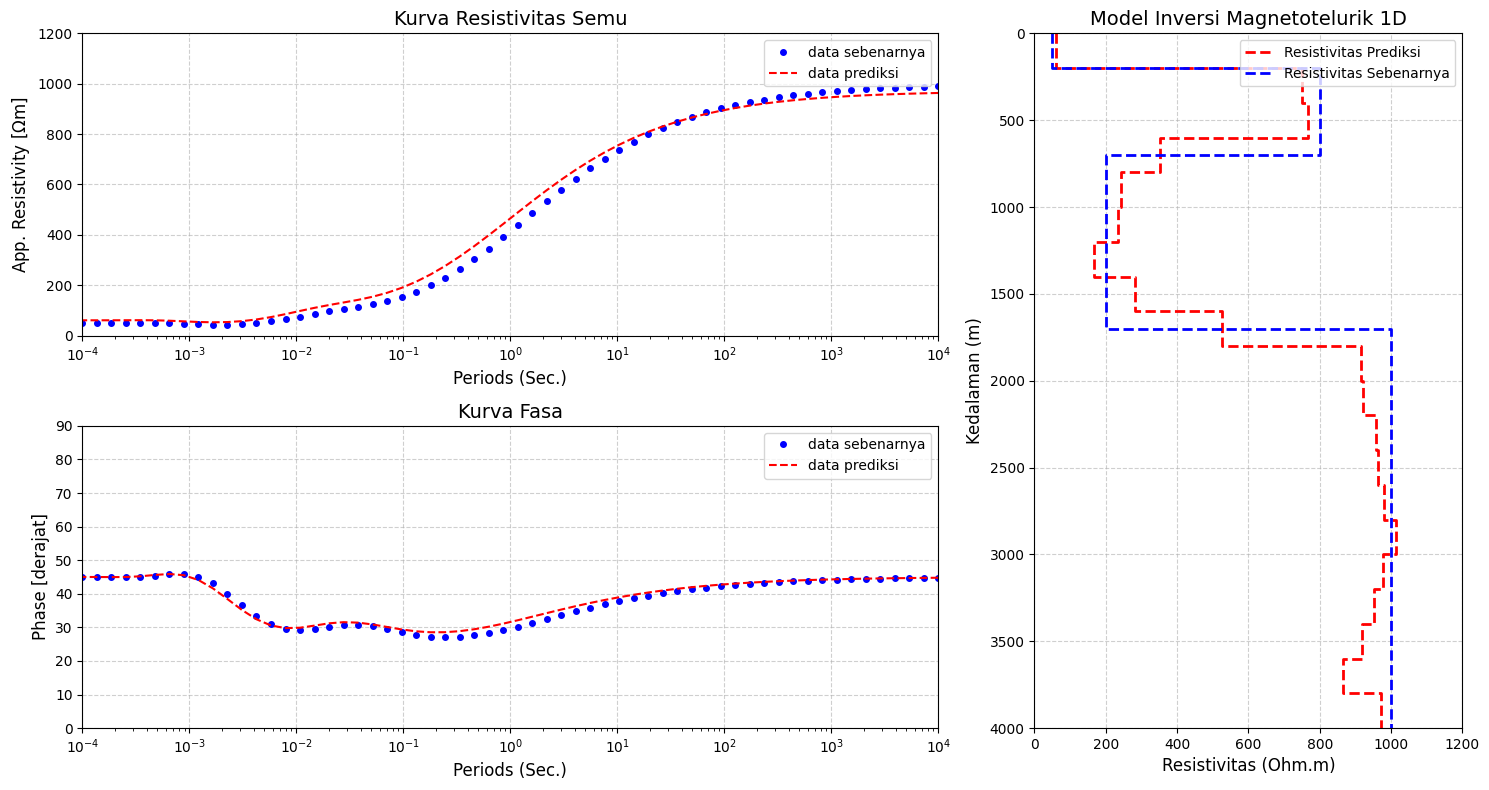

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 734.42
MSE Fasa: 1.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 12.92%
MAPE fasa: 0.52%


## Model Bumi 4 Lapis III

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([50, 1000, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step
Nilai Resis_True [  50 1000  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [ 57.743923 874.61615  815.6593   502.24414  234.2408   227.39857
 198.51656  236.9306   439.24023  753.68445  782.6851   789.5649
 807.4144   807.23804  814.14526  811.08936  799.5779   755.1994
 755.23785  785.8338  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

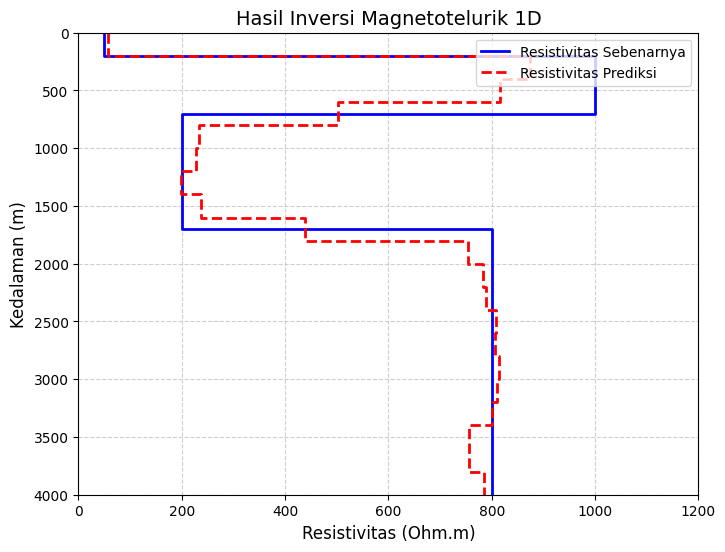

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

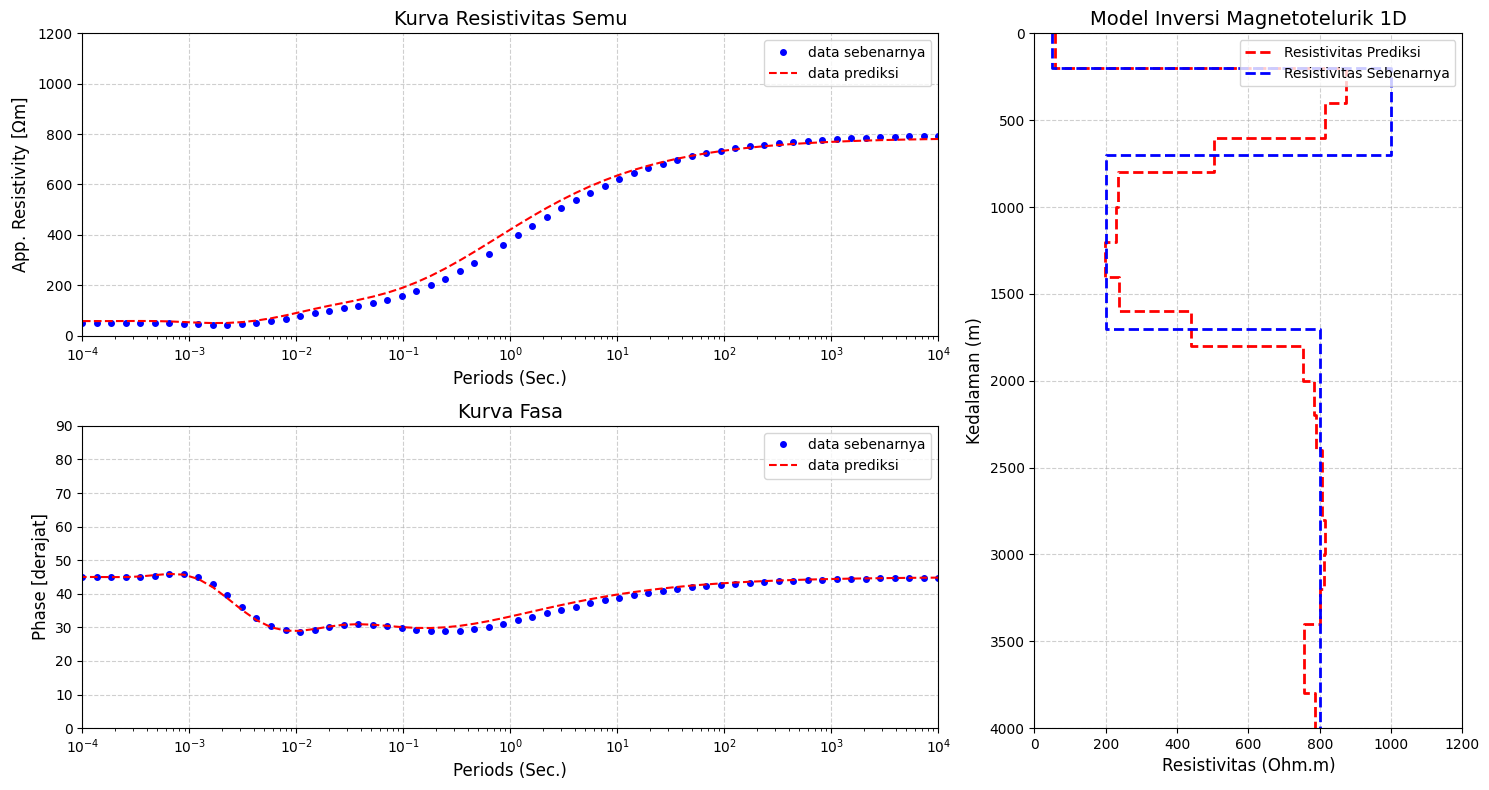

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 445.95
MSE Fasa: 0.61


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 9.88%
MAPE fasa: 0.34%


## Model Bumi 4 Lapis IV

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 200, 50, 800, 1000])
ketebalan_true = np.array([200, 500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Nilai Resis_True [ 200   50  800 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [192.91953   44.70817   29.004389 262.2473   767.9554   854.25604
 857.65436  868.31366  888.57434  883.34247  893.80426  921.58167
 907.1414   922.1279   956.32263  980.7895   987.9678   957.2171
 978.15607  972.13116 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

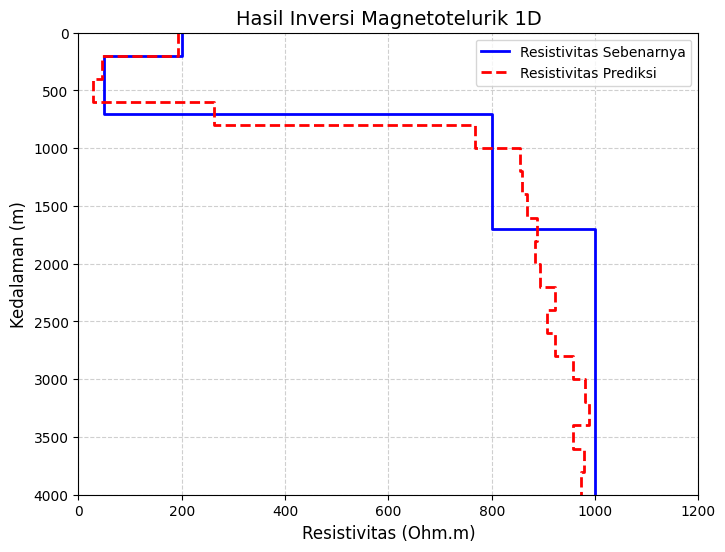

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

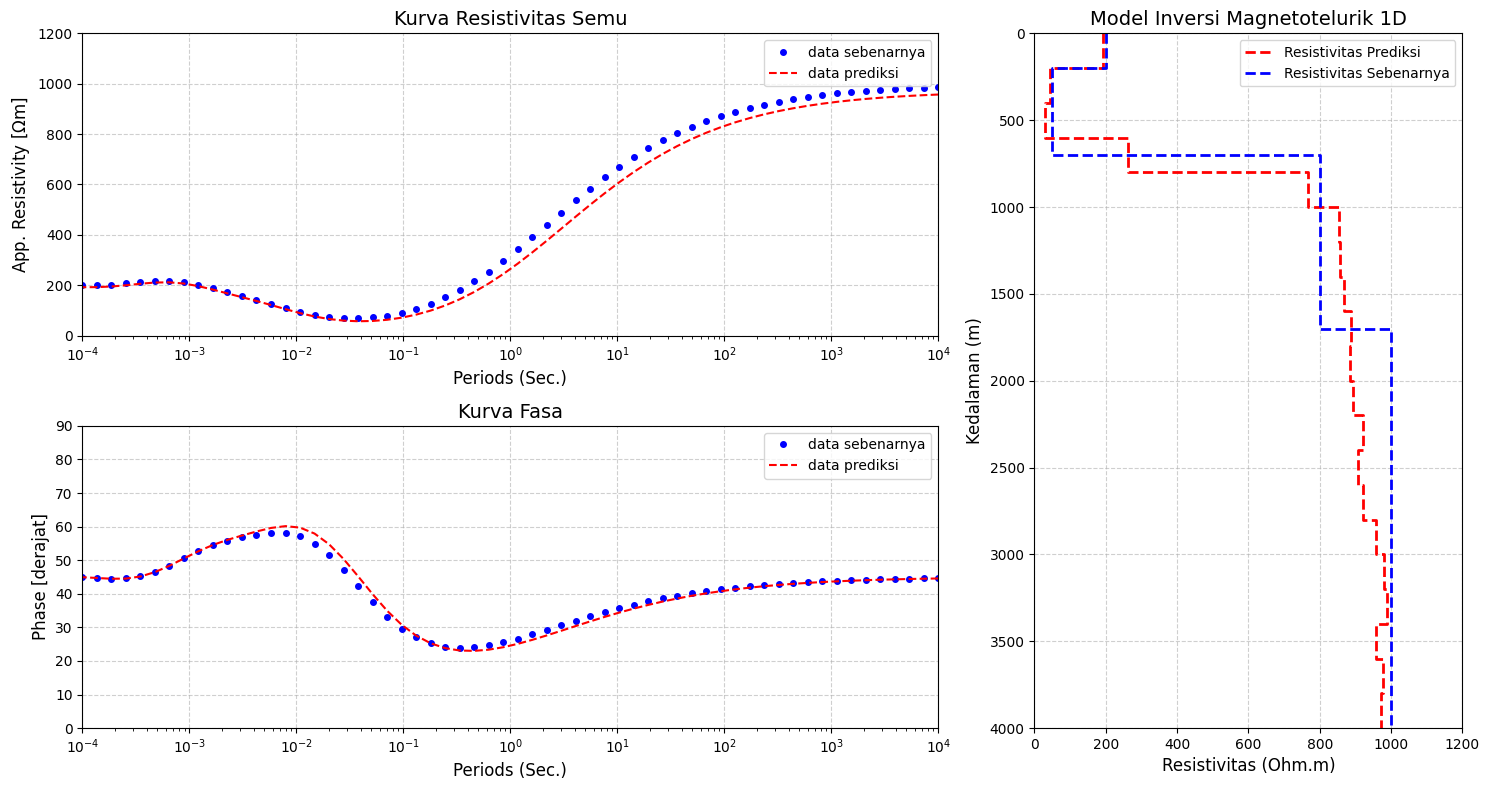

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1324.69
MSE Fasa: 1.61


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 8.43%
MAPE fasa: 0.63%


## Model Bumi 4 Lapis V

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([ 800, 50, 200, 1000])
ketebalan_true = np.array([200, 500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
Nilai Resis_True [ 800   50  200 1000]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [791.0294    49.730736  13.35305   81.66665  349.1645   145.81383
 125.47206  374.32187  646.1074   774.95215  856.04614  913.796
 919.9206   942.6498   984.33813  981.9541   985.76654  983.9221
 957.84076  990.31445 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

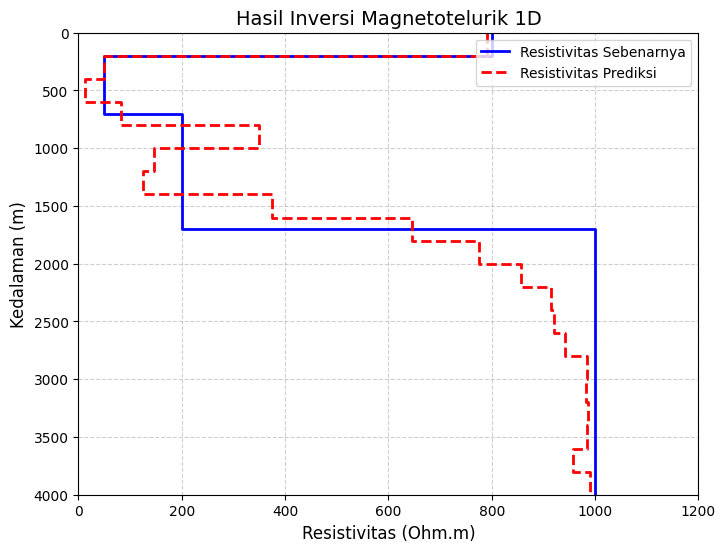

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

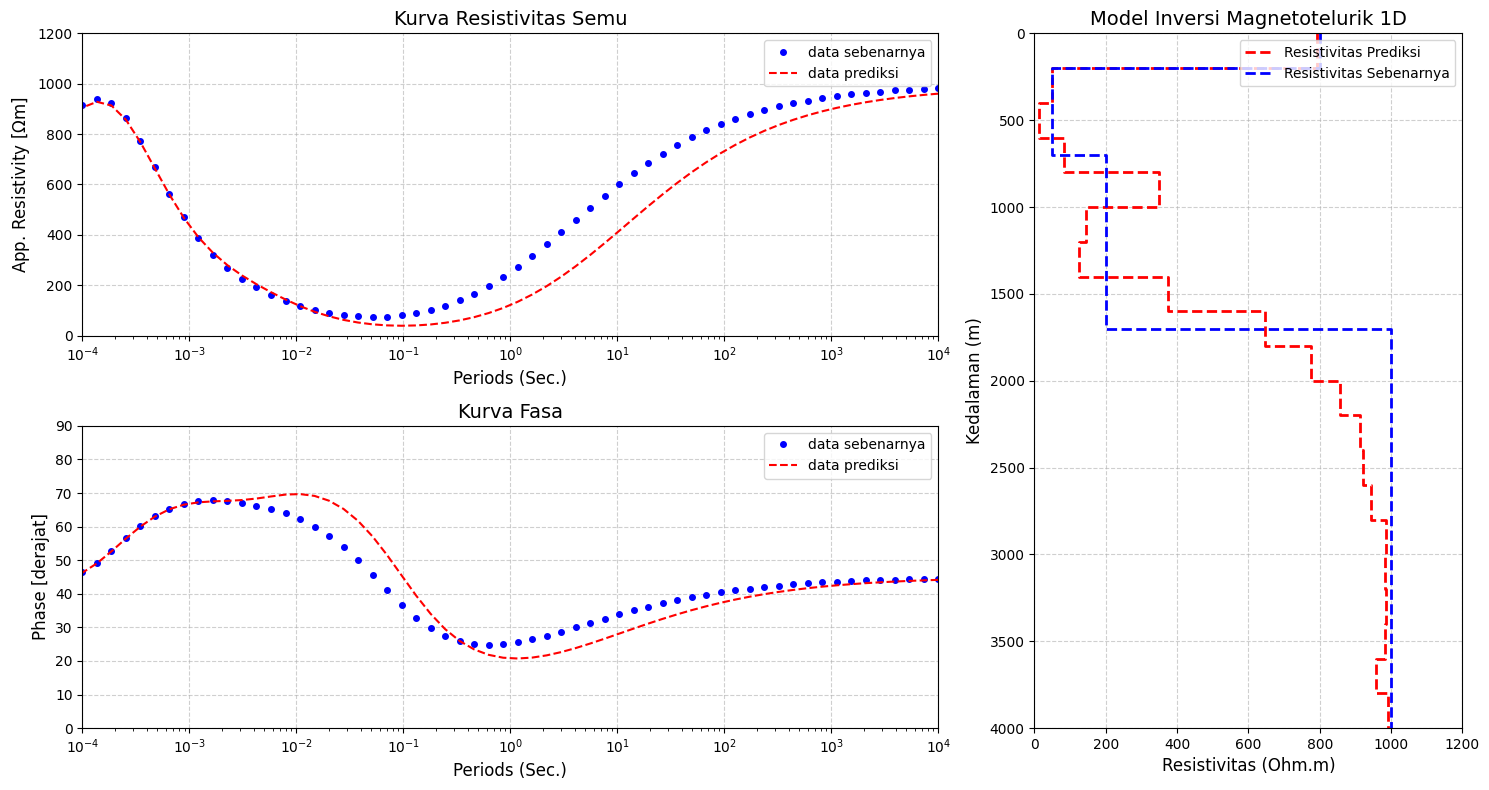

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 8474.96
MSE Fasa: 23.65


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 20.04%
MAPE fasa: 2.32%


## Model Bumi 4 Lapis VI

### Prediksi

In [ ]:


# Forward modelling untuk data input
resis_true= np.array([1000, 50, 200, 800])
ketebalan_true = np.array([200, 500, 1000])
frequencies = np.array(np.logspace(-4,4, num=60))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu)
fasa_normalized = input_phase_scaler.transform(fasa)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0] #
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict,ketebalan_predict,frequencies)
resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Nilai Resis_True [1000   50  200  800]
Nilai ketebalan_True [ 200  500 1000]
Nilai resis_predict [990.66675   29.950172  21.106604  83.42174  380.64868  180.26785
 139.25137  252.55826  507.45023  648.69025  743.9207   791.9682
 808.14374  819.7894   832.55115  831.06116  821.8033   788.80457
 772.2103   795.75995 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

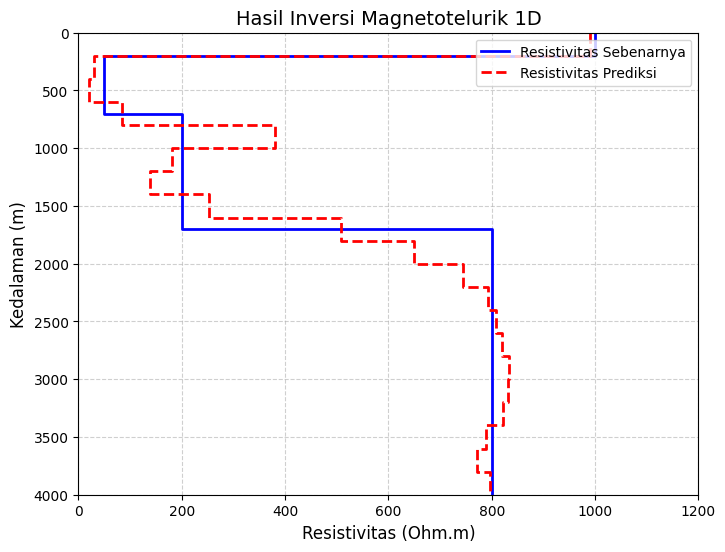

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

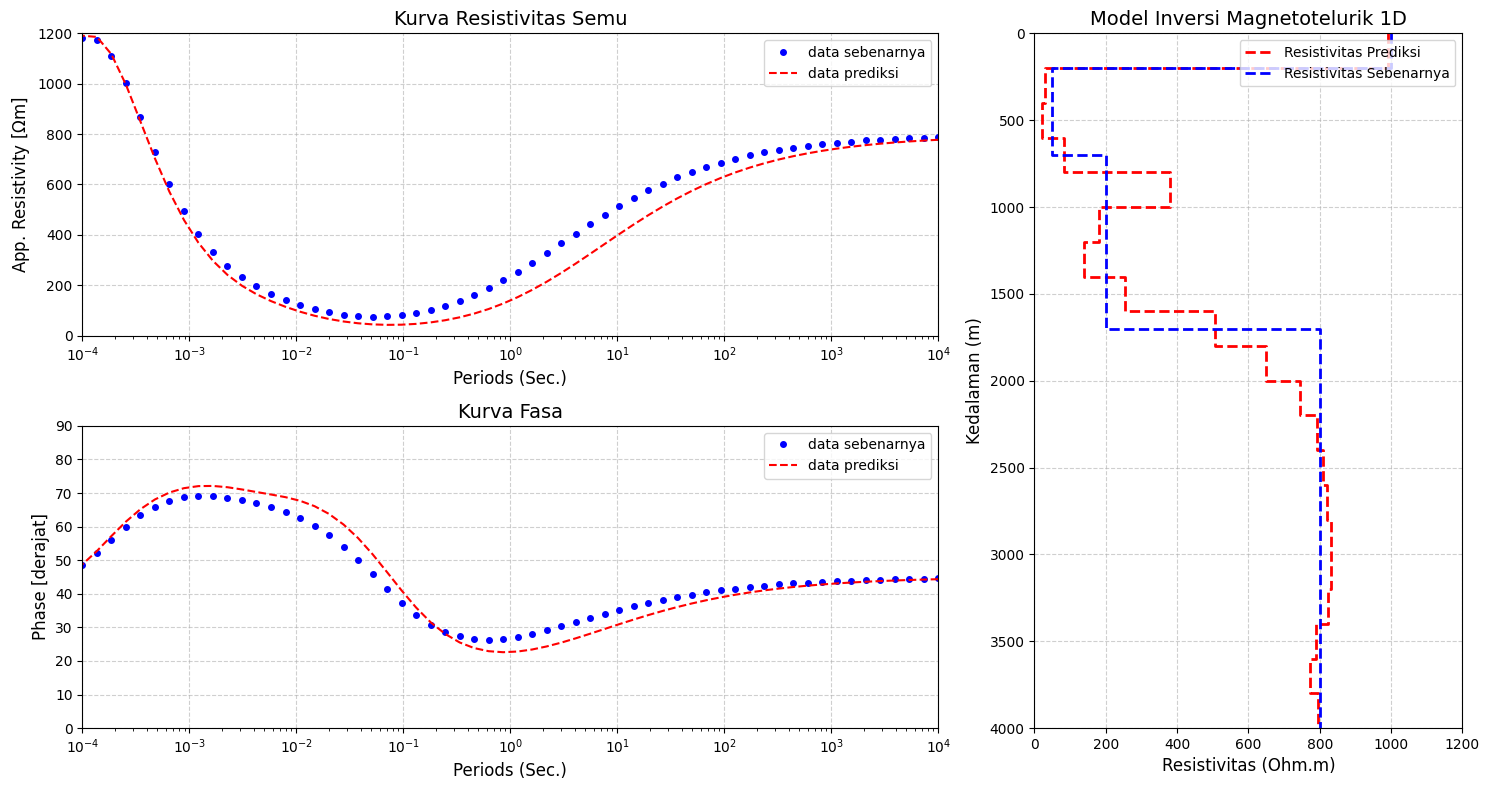

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

# Task
Lakukan hyperparameter tuning untuk model machine learning.

## Identifikasi hyperparameter

### Subtask:
Tentukan hyperparameter mana yang ingin Anda _tune_. Berdasarkan kode Anda, ini mungkin termasuk _learning rate_ untuk optimizer, jumlah epoch, _batch size_, atau parameter arsitektur model (jumlah filter, ukuran kernel, dll.).


**Reasoning**:
The subtask is to identify and list the hyperparameters to tune. This can be done by reviewing the existing code and writing down the identified hyperparameters and the reasoning behind their selection in a markdown cell.

